# 미션 16 — 상영 규모와 관객 변화로 살펴본 영화의 역주행 패턴

**제출 관측 기간: 2026-09-23~2026-10-06 (14일).** Cine21 영화 정보와 KOBIS 일별 TOP10을 연결합니다.

1. 관객·회당 관객·순위의 개선은 얼마나 관측되며 기준을 바꾸면 후보가 달라지는가?
2. 관객 증가와 상영 기회 변화는 어떤 관계이며 공휴일 조건을 좁히면 결과가 남는가?
3. 개봉 시점과 관측 가능 기간을 고려하면 TOP10 등장 지속성은 어떻게 달라지는가?

먼저 관객 변화를 확인하고, 영향을 줄 수 있는 외부 요인을 검토합니다. 자료만으로 확인할 수 없는 원인은 따로 남깁니다. 관객의 추천이나 자발적인 리뷰를 수집하지 않았으므로 입소문의 영향을 구분할 수는 없습니다. TOP10 밖의 관객수는 알 수 없습니다. 0명으로 처리하지 않습니다. 회당 관객은 좌석점유율과 다릅니다. 이번 기간의 TOP10 등장일수만으로 전체 흥행 수명을 알 수도 없습니다.

**실행:** 위에서부터 모두 실행하세요. 기본 모드는 노트북에 포함된 수집 CSV 스냅샷으로 재현합니다. 새 수집을 원할 때만 1단계 DATA_MODE를 바꾸며 기존 보안 비밀 KOBIS_API_KEY를 재사용합니다. 키·인증 URL·예외 원문을 출력하지 않습니다.


최종 정리: 2026-10-11. 분석 기간과 수집 자료는 고정했다. 관객 반등을 탐색하며 입소문이나 프로모션의 인과 효과를 판정하지 않는다.

공개 포트폴리오본: 전문가 20자평 원문은 배포에서 제외했다. 별점·평가자 수·관객 분석은 제출본과 같다.

## 제출본 결과와 보완 내용

140행 → 전주 비교 52행 → 개봉 후 비교 50행 → 공휴일 여부 동일 28행입니다. 개봉 후 관객 증가 6개와 회당 관객 개선 12개를 분리하며 엄격한 결합 후보는 암살자(들)의 10/5 하루입니다. 이날은 대체공휴일이고 전주는 일반 월요일입니다. 조건을 좁히면 엄격한 후보가 남지 않으며 이를 입소문이 없었다거나 무료표가 영향을 줬다는 증거로 해석하지 않습니다.

성장률 0·10·20%와 연속 1·2일의 모든 기준을 비교합니다. 개봉 후 관측할 수 있었던 날짜 중 TOP10에 등장한 비율, 개봉 전 시사회 관측, 영화별 판정 가능 분모, 특정 영화 포함/제외, 외부 행사의 시행·취소 여부와 실제 관람권 사용량을 확인하지 못한 점을 추가했습니다. 결과 표와 그래프·출처·참고 문서가 함께 저장됩니다.

Cine21 상세정보는 기간 내 17편 모두 검색을 시도하고 제목·개봉일이 확인되는 16편만 결합했습니다. 17편의 KOBIS 영화 상세 정보도 추가 조회해 감독·국가를 대조했습니다. 원자료에 없는 감독은 미확인으로 유지합니다. 제출 모드는 저장 원자료를 사용하므로 재실행일이 달라져도 같은 분석 기간을 유지합니다.


## 1. 실행 준비와 자료 모드

submission_snapshot은 실제 수집한 CSV를 노트북 안에서 불러옵니다. 압축 문자열에는 영화 공개 자료만 들어 있고 API 키가 없습니다. 제출 기간과 재현 결과가 고정됩니다. live_fixed는 같은 기간을 API와 Cine21에서 다시 수집하고 live_latest는 한국 시간 기준 어제까지 최근 14일을 수집합니다. 새 수집은 기존 보안 비밀을 사용하고 JSON·HTML 원자료를 보존합니다. 출력 폴더는 기간·모드·실행 시각별로 분리합니다.


제출용 기본 모드에서는 저장 자료를 다시 계산하므로 API 키가 필요 없다. 새 수집을 할 때만 Colab의 기존 보안 비밀을 읽는다. TOP10에서 보이지 않는 날짜는 관객 0명으로 채우지 않는다. 제출 자료의 CSV와 데이터 사전에서도 자료 구조를 확인할 수 있다.

In [1]:
# 1. 제출 모드는 저장된 원자료를 사용하므로 키가 필요 없습니다.
# live_fixed는 같은 기간을 새로 수집, live_latest는 어제까지 새 14일을 수집합니다.
import requests, pandas as pd, numpy as np, time, re, json, unicodedata, base64, zlib, io
from bs4 import BeautifulSoup
from pathlib import Path
from datetime import datetime, timedelta, date
from zoneinfo import ZoneInfo
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
DATA_MODE = 'submission_snapshot'  # 제출할 때 그대로 유지하세요.
assert DATA_MODE in ['submission_snapshot','live_fixed','live_latest']
END_DATE = date(2026,10,6) if DATA_MODE != 'live_latest' else datetime.now(ZoneInfo('Asia/Seoul')).date()-timedelta(days=1)
START_DATE = END_DATE-timedelta(days=13)
RUN_AT = datetime.now(ZoneInfo('Asia/Seoul')).isoformat()
RUN_ID = datetime.now(ZoneInfo('Asia/Seoul')).strftime('%Y%m%d_%H%M%S_%f')
BASE = Path('/content') if Path('/content').exists() else Path.cwd()/'work/reproduced'
OUT = BASE/f'mission16_{START_DATE}_{END_DATE}_{DATA_MODE}_{RUN_ID}'
OUT.mkdir(parents=True,exist_ok=True)
GENERATED = set()  # 이번 실행에서 생성한 파일만 ZIP에 넣습니다.
SESSION = requests.Session(); SESSION.headers.update({'User-Agent':'Mozilla/5.0 (educational movie analysis)'})
def save_csv(frame,name):
    frame.to_csv(OUT/name,index=False,encoding='utf-8-sig'); GENERATED.add(name)
def save_text(text,name):
    (OUT/name).write_text(text,encoding='utf-8'); GENERATED.add(name)
SNAPSHOT = json.loads(zlib.decompress(base64.b64decode('eJzlfW1vXMeV5l9pCCAwg71N1/uLg8FAkj1AsItkgAwwH0YDQZGYmIhEeUnKWSMTQLZpQ7blkb2RxnRCaaW1HNsDBWFkOZGxypf5Oermf9jnOXW7+95mk+puvjiKJ2Oqu+/tW6eqznnOc06dqv7FiZ9d/vHy2tkL55Yvvn52/fKrWi2eX3vtxIudE6srVy5Vq+dWfiZ/vr+yvrQir3548cLJlQs/WPp5denya8tLpy+Uf39wqbr86tLKS+vV2rmLS2snL9UvfvTKudWl8rI8Q16efuXcyk/rj0+eP1+du3Jh+fTKuvxbbpNPyl18yZvWzq+u8Ka1Vy7/nP9eOLe+dGZFV7oyqfrh/3ipMsp4r6yt+rdu9t981L/z4d/0fnX/b/l56KrcNbbSJnrvQ06qsnox8b2xzsv7HIxbDJX2ymklt2jrXJB/jLaVd9bGRYMbkk+4z2lf+eBs4/lnVkxlKlX94OV/FmmCDrraeetq//OtFzu9h1/07271/vhR//Zmp/f2496dzZZoSnlvjM6qMn5RN9/j5SL+GpVy9E7xA2u9G/1TLhtvI95EXdloQkssW9mqa4ajpAK+1t+837t5s7/xuH/7UX1z6ir0ySd0V7EZu5irnHU2SUMqzdHBAKaQrcleVY4iVQ5C8Va0ra2J2eERMVCQtgyuck0ZgsV3+7cf72w8Gt6m8Q2jIh5iVeUXfdXN2sUUMQldkxdt5ZLFvTZGiIPZ0FVXK/yv6lqFmXFoO+kqRExSyLrVOoQaTUwIMYSq/x+Peg/v9+8+7r93/8VO/+ObvV9tPX14vX9no9O/9Un/zzd7nz1qzpBBz623TlUBoo3elfEfvTdQIVP/ra+V1yFBy1JLrFCFKg/HxGXlqqfbV3vvfbZza6vTf/NB785HLSXJUInoDMYeU6NTSkrxnclQTQ4eHuH5AdTGosXkPaY+RYuxgy5RmTFA0JqWELGKVdcNpAheOwzO5tdUjbdHOsoeZGsd5obNJ0yJci5mvOtmNJ40NEFBI9iIDXikTkauqSrCxEysnPFVSK7VeKpSs3EIq6re3Wv9z6/2Ptjcee9xB+rZe3zzxY7qPcSnjzu97fsjhaHSGZsN1dVQJgiIHlBfOEBoMMKUKZJKsImuSZGXoJ42BHzg0Cs/JhF0vimRobZBRXauX6coH9zsff4FrPnx9d6dLWhMp/fuo07vg+2RFUXoKiZaRxc4E4vEmhRgUlWiPVnohAqaAOOMhUwyVBAJI4m5xTcCVbetJ5o9aCiwS9D6nRsPoCw77z2Bvm70bz8pArX1BQrH4VDQ2OGbGjBizMHxPVSq/lNfScpFKC3+c7ktBtBWTQu2JqWgcnKW4Mr2g1beaUcJTKA12wx9wUeK9zrOEuCNY6Yd7odyqUCgjbHCeDV01g2AdggmswAtEAX3B1qqoEa0KjtK5SJtNSRoK1QbYkBADzlUwGBb4g+Qw2VadcAMU6ObIhFk1XQYq3WCuwmKBsmRCBbuxMpbIClGGXoag/cZ6Aa9gMsCuFkHh6Uz3RbuTh5CBU+fZnVLDgKtehbOegyuC0TxiKG2MDydZegxCKmCJ8kqAokBw17Daq2O9DTWQ4M97RzAlWF8UedW2wVmB6YzH8wmY1MwdMloDGDvMT0YBUwVVQUoRsCjQBi7aCvKCz8dKQ2GSduWQARYNT3Agg1YaLVi4wZzruDukigK1MPnmBPHBKaBGQF3wJC4osgYUh2B7za1mie0qimQ1TiVAK2G7eJ50SUv3SQjSRADEyIQpyO0x7IVnSBgTNoD5x00I4wZCHFVHQBWvfNUfMKqBlBpl/jGUlvAgBRQTAwWUwWBlMVMJSou2FOmsURwo7Z5EFbVAVEVppoUyYGgKsYFagtYDURPaASsyGR8EEmSrA4Or8BLaEVagJVDpFpSFWANI5VVXle97Zu99+93dt76cOfjzd71q53+5mc779ztbfymQ23+CiN3Hcp7v9P7ZqP/603KC9k/+vDpn56Uvx18CZDY/3hbvvCrLVrAwxYMOQMccgLNAcMK0IGiV8nQb2EIATlEJPIFC2yEB/W4DwpEHkKDbQ/uTMAMFQeiaM8GqL5Ak+wwkqQVNDMQPLjNkAM9FFgxtAGUC9Mp2AA2YTW/FAxguUk0/YFgOSW4SZXJd/MiMEw5smu6p8i3HnCE6bdCYaLlmEH7gciLov8GQQBUEiMTmjPsZ4NloHuOwRKH6QvA/iGAoEEiv7WK5MLSGPEGDJdiek38EfpL9gVYiklspD0yU6FyBAJoGCupAkHB5ZDpPx35VgDaqoT/oOAxkUjCiDCbmg7EgCRDS7RgcrtlYrKeAQJNjpq+F5YPxg5KjZkRQgU7SdlrKzEKtAVXEaLwCmidp/roCL8YXKt5IrCeBgJBYhFAhLpdjCagnsyffU8kTCDRvKqC43VwKF7LVYJPIPIjHIhNs/A1szUH9EegB7DFXMuFDkTNEegWBIYHBNkljCRysq6z0cm1DK8OExe34Jp0zh8cnKF12dA2tAyVzTAAX3NtDQ8FV84504UKa8QfVTeROAjRgDYjnB0zk0OBZ096RKKKtqDkqXhxD3A2LkG5qSNAEnhW/Me5AzSDaRjhvIgzWxINOO+xQzNwyEmcrWBZVDQQAgkpPIY3SWCOt5a8C2pK+m4YESbOvAEnMNG2OzITOCP6xZgI+Gp41C71Q3sqnJIAPEfEuYFUwUEERqPwiKIIwCcvjJCcAAjTsMNwEGg2OhPoJeqmSPAUiLRjEvIK84ZVpYx4hpcdwAKeWdNp0D4CNE4zm2FjZb1TLZFmgeboHJAwaGk0VWTsjjrvBZhJjHKQRA44gCEbA0mGKyNdYTIAg1ohFCFHNC0ZpsPlBL6ePKkFOtzF0EbaLGbEVfST4k9xMXH44aqFn4AkI/wEJlG9Q2612uLJU2AyOCAEYKCE7qLjSWbeWBKfaD1DSoYuIOvg7gzePMYeLCLSrDx9Zav5FiveD5Mxr4hRYwmuA4dforWAfqesMvwP2ZiBNhlGComXIlhMIkV1gBqMWqvlNiGeD5Az8EulOuIPYHye+GskOQclAlPhTMF7SoZOwwwy3QR8Jucfo9F0zeHgaBwU0FcC60XprJUAApGBo1MAHpfYFmzCSAYHBspLMUbH7IxhWqsl0GFgcYL+w1EWLGbIBj8G7bXAYmsyhtADYUSwiGljcJul85QOSpPaCvOtYTFCIZBjVWcwEBEbArMTR4dxdZZe0EmGB74HBJkXLEwKxgGTy22zmy1/4X1y0Qv9C4v0o/CsjJqFlChJBXvmm/B/tAEEaXQXGE4Fl2AzgcmHoJks9gy5EcGPnh8PRJaZs4DTFzUXlhaEl0miVJPCY8IT3ITAZU7wrF2QyUx3omgL1FDmnBG+A6xTS6yZ8hgg6Umz/0BlPB0IDPdk6a2shBawBeZaIuOuDI3ECHkE1fjHCnKDHclspYKSviXJdJkMgDHGI1O72b8Et6BJNLoyaxFWwMBBtCZm5sGZl5KrkYyFrj1ATzhXrdZnxWhoC7wLmQF9BLQnMoyrSRnIQjZy1SCGYCZcUpGJLh3e3XqhPwwsmiJMjdNwuCBYqqQPutRbJmlktukHHKYIxs2HI8TCDZYzYGhT0BQ6a+dIGWyr9cPAahsDuGkYCAZrMGQBXcR4moTFAqSFWMCHUo8tWT2Cr8wFhEwWAVJlmz47HhywFdtk4lroMzElMvimSoAjZ1qHBGEgWZGDBQ/Ka8y4S8qMQjqfWzIdBmb7yLyfKpiN4Us+MSHMtQ9H3E7gEkwbwhMzcQwPR0UisWe638GOmTTQTWcfB9g9CsEEn57+6Zv+nc92rn/Y6X+zCTH63zzqf3IVU3r7Mea40994IMjzzUZv++rwaVbIZhTMJYwgzGGOu862MxTOhbiCiZE4Uzqm0VRkChHz2DZvorGeC/9Ap6BHnArpvQSDOhS7DoyHSX2AOfRx4Kba8BZFdojZ5lgC+EAOMpQeYXxjIlNB5a6e1kkEBOHA/SikiJLAlCMIMyPmKAgXACxgHWTwAbPp5B4waFx3tAFYHa/BFpiLbjKBNBMWczUOrNxK7gJqi2kKlrCFIXHiFS3UC4EDZUOkTQQISmteL1CcSFFixcy4bsUwqUDxDEkE+AUMP5MIQWIohA+ZjpEWLqsvkbggKQNHve1maJJ41SCowCgmMkxMLSkIyY252cMjaKZnHTODXEjtwmwQEXFdqhsL5icuHvK6ljXTLgbGB5mPVMVAq4OzTkxumlbz08IxM0PWSAKPrkCDs+jAmBFYQsaOYBgzKQGUYkYLygk8Ym6BqQ6facEOHQGXbbV/CIAcrfPehZLfxmA5ru7SgkMBZHQ/alLFIEOCDzAQ3ZDKqoMhaYAPx0Nagh0QkJlbTr7ONXe9YdaLMnm+R5swVqF4oA+SkYJudp3wK1hxcqImLqmWSIeBxxpimJBqPAYPZQqKY0WuAzanQkCEJEFtpIvIdF7By1qeBd9iKJ7aeJx2reUZ6U/vj1d3PtnqvUmpPrjZweg1l/LEqHVZ5lSLcfSmLNiBBwJC+BZhav2nXKDr4ki02m/B7jPwDQiqQLOVxFcwFbgfAGoUnRX0igj9fGbaFpEW0S1QkC7zX2Ce4JzMSyAGc620ZN6Fs7PAvy9aa4aga0B2pWig8IrMZICDHSvGf9bLHVFWpJmMwuewRXgqwKC3LaFmwFuriPIClk58IWhFyRN2JQjW0A9cN/AHZXUVSpvK0nQU1pcKBgXYkmZOvylHm/lOAbewZEe2ybQ1YDTKwkiXATJiD2C+MRKCUhfBG8ixKKJzXhLqpp0hyOPkdy+ghdha3DCz8DEjypHqCKBoVDF5yebqsqTLGFcT3yLpYCzdhkm1Wp0WYKFVxpChycgDvzLtuxsl1QgkiJFjgelBR6O4WnihFBLzsdAdMN12u4cArIHk3o0YOFQsiEgsQ8A4G03+7YNwkBgYFhgu5zJfViC1PQEHhVRgOPhjDalMBpZUsF0UtHIGET4XFoR101BgIlIj4Dk2FoGYG9OIwwBUo0KE7y3rd+QEwZdqGswaGIfSUokgdD/RggqzhUeWtV7WlbREKkjayO9Dy4BlG72HGxgoYkf/849625+NVAehb9a5wCiCTl+DKO0Rlps1F1cYJhO1JOPgaJlsR7dblkTCoBrjQIwaOiA0nz5ZeNrofV2OAZaGGRMrQhiX9fCfchkmrKXeCvPmG6vAVs1MZhGsY15lMYOhs1XZSApBahJAHbIr69BwP47tS8WZ5N24XsggVnlS6sY8UQopP5sT6hE8RFmC00LmtGbsZgTbKAGolZM6KARPSVgj2KSIq5g0lxxHYIJStyQSOjtUnCldMJwpRJGSQMYYLDuyWt5CrWUdMilXagYd9NdwjTdQkYDHTMJBhRFvU8PT2DQJr52yPg+2R3YdS+UGSEdMTpLRmpSOxYpMNGSpTJOqKxY9CQstJN9HwG7lDRfVVEsKom9Dimd7HVZA+KTqjAfLZRLXTkkNmM0B5ACjpUogcFHM0wXaUkDA1UMWxJnYlqG9Yren42G+W1bIpehL3JCwWMMlGxBr6oITs6VqdI2WnIPnxcxMSSW5/Ebii21LKZqZwv1EcBxXaiO4/GnpVqUZYfeOxRyaRYuRagd5h6uFLGVMuZKU4ljHpepMzw/4hpy51BOQEXkEf8KhLQMwI9wkMwDDgBMSLBduLX0V8x1SHMHUh2vJNF51ZkhwKcf2l5iTFoi5kHP0BVaHbwpAAb+hknwbCBfyp1yINHBdhbZtzsZPFUBIs7jOaOk4OIfzZdKZotCwDlk6ofP1iguhmA8pBRRNTIjVi6QR0zIwS626Shf0nA+2HCLQJGtERuYDTSfjSqjHEVKR1XCBg+SyLK+Dzlqx4VwWMawti2ZMcreEatfyHsz3uMASC7EjikWu5GzKuqRRZK2d5Vc6svqpUKwAJsMwgC4zo4usvBHIDy0pWwR2Snw1tFbNjEWW4DRZzg5bdeQImDZb2Cbcn5X8ZbAs1WThERPAiQtPrNFri9KmsvtjKyJMoLwVTiBmlMDgiR1BMiigyxicxHnFuGsxa9hezeVSZHEAl+eYcm3JMGMZmubTpQKM63hddFxJ8oQ0FsiCEJ5+mIkOR4XOpLi6ZJNAjXNZ8/NtZW5x3L2AVTJGQ1y1aEmrGkVY1xJJ5ktSLbFsN8vCAitDIK+FdwPkV2HgVuqG20x2H1RlmmRQeocWSx1eVyq4HOM5KZCEp2Ug5Tg7XIxOmHNyDjzADhat6obbjHV2RIXeylhoialCFuGYnHYsf7Es2ROtJZoIpTekBYa+AcYRuNjXFmg8EztXoKGjQQRuC9DD+ct0LErlZhpUxzkJdqkVqWwNyIEFMlVsa+VMy2EhyFrJcCcAqHu0BFprpWYYMOJZgUflqLdNMEtUVkGzrBsXdmhyQz/MGMoeMDsN186Ebl2oAHQ32TNBY5kWMMxVMKPDNLYrXous20j5fmbVADmsHYZitYAHoK+ISCLw3dclpNoyxJBUVYEMKFBWtDFIZMQxgitWxXMhus5Sk+0kUaFbMs2Fr8GBwavI6rIABhjQQpIVRCgS1/FUSakY1sBIIV5Zh4FVws6YJifeNqWYAVotGIcKZb8EVyBTClLQYIPkHTFxzrLkS+I/sGbPh1kpa4H6wC9ofkQ6356cWZGVhFVqlIgriGKzZN+FuWlguw1SQQowU7LdgjVTixJ5Bi7cZ9ZytWeCuDpNfZtmOlyKPC06ZQHppeicKeLMRDyGhNXeTNygI5G1thHhKgueK8mgGdtqWOjqM5Ph8BYuSi0x6Q4ij+QKKxEqHFlGnqRyxVaykceRpmKELAIWgrJqGysx9YAA5qF5iYZHwmZjBlekcpo6mOUWE06JzUE2IAg1lconBDVMSGK0WiIVVD0Id7aMkCTGlMAxACjKdoDErTsBFEzWTrNUXjLdTA8AtKxh3oxpRIvAHgzQwH+o+8T4YguIdFhjLWkSYhpLhbWRnTYIqcDdyq4FFs4z4HAsZpWwnGUvTfi3syYHWFWmEPDqmmpjChHvadknxniPfi/CDQrTJ991vIUl8lIdx8UpJ2mVSJfRJCd2PO86UymEZsWcrOLLVgqPd1kWURM3K2jjImxZix+HZ8DIwG8ZVkgQgIE1JE9aojKubjSFaq957YtuGGYnZKnipDCR5RNZc2LlEYItLys8zFvgNi2lu3haDiUH6Dz8VBUINjq156i94jUl0JPFWqEuodB0FprTyskmuYoDki2cHhNC7xxB6aOol2NxRpVE87xpSTLrTgpWNVBjJBuDGTDiUoSskzIxltSCLdze41lKnSTisLmsvNAFtQQg0I4K9blkX2Eunv5hu3EXewANYDRuSoEBN02yntpJ+iMGXJOFNxBdJtKCZhoa4QwV3BH0gAd5TDtbDHbvZDgGM6sa11g2pFl+FVhaxYy0yaxdkowEy8Yx5F74K6Iew60mfJ9azUpKYJp8BEt/YvZCVTP3pYCYST0gBpTL9QBQqWmX3SOGa0LGy74Im4ix3BLoVavpXZg6H1WFGGA/Uj7IvQ2JpeWkXWIVQcrMswjGdbKomdNMerH+omblJulIW7JZsgOa5RQAxyzLV0ywMgUgaRC6Q6ArLCqz2JeVekzWcW+NAByuGsaCtEnu53Ou4XXcOHgeMAXsuHpgZUua1PxGi+CDmwHqHA1cmoW+C612mlywGyxdNDe+ZrJZbkgiewHKq7agB4BWa4CjDD6rUq6TuBFap7rYi5OkMJ8cMG5Y46aQKNvESrCMeMGR9mRLtmNaQrXXt/aFVmgJ5iRJkoakJZIpSomCpDvBVr1kNRErm5y4E4ErBRIM03kaMKfAMnwzNi4t7jo1sLLQk6BGYO2y/NVLGTD32iZDUQVWuTOsy6q4riwicHGS+xRo3rEtxayoygIkWbRgBzH4zG9KCAO7d5pl9oKqgRt/uSmEtIFcAUGHzABXfFoCtOjrntjGbV1Wx5LxBHt2Tuva4SZuQ4EdFdYs/iRIth7kFbSegaeSuWk12yave6K5hcoplwuAdNHfSFuWbR8MiQCpZSuOZkWAoT1QviR10GBlycdWq+2MwD6AyhW7LKRKdmMiYmND3MWauTMTkFmUPjBOA2wQ0FhzBANkzSlYbavdXeWz86Epiz6tKSjP5EuWbQkSuiTSqyiLvLAmJiSY5nWyhAWDkd1JlWlmZmbdNca8E/hTYjSt6qKeTMOps2OgUojpcoEDlkpwjTMoJj/p8h1GSzOYI99mZfhQkPFtYwfEUssknA8lqDOyQ4NbnX29GAub9cYXPmg1B6yLKSXmyoqXVNYx5GXRoWkJOT+QYtZiKR3RUqMKJ4OBM7rsKdHM15A7yJ6TTLeIW1hKx6V6WT9mFQHFCtx80ZzEXRvL9mepmlbsXb3k2c3MBkihQMk7YwYhgpeiMBd4kkM3KFk5EXJICg9WV4HqCmttiTEPnMKnwbIYWzFC6CYGDT6WxRJupUFUjHmT+mupq0hS/6NlJzYINjg7k4F08i1RiKnmmdAC+2ehVb2IAxdiZG9vN8nWc24YUYWuSaoRd5djDpwiL2Ukk1S7WSLpVGyNFdnG+BrUTKSEsdSucPVZyrYlPSUpIW4AMnWxbmYZHXdAcFdoWw2mywZk8h+pluf8e0BGAVSpbk2WVSLCljJpMBCVy4eWiUaW2ic5SwJQblstH0JKgBvqtRiELOIQArxUJuq6yguDKQsDRBimYFk7LfuANCJOKfmDTC615NqVbSWHGMEKbJTlCref9G5sQEE/v/30q7v9P96iHX/2pMP6gSdbuNrUGRAPZcpGDwY4IM/iiaWUJis4QWYIEsHDcAlcNkujU9wAIKWvY/LNgr5eYUplGdOqUlPomZVgnAu3SHG4iRcT6LloUOp84LcCywoDBxGvg1Q2kI6p1JjC8b1hB8NfVj058VKmCAo0gfVYWTySrZyKRfeSwqBD08RfMKRh+WXWhjuIlLjxlpTzA7CRvS2S4ZFF86jgBLSYe1SiRYpbPaSC3mRPHSMMexk7hsU8BAfmx11cybWlmgF/NY+2kQSfrAJ2Hfm0MbbMYZasI3e1ZDnChXvauI2C+FXXChsFXGWhuGOJSluOeQA4Q9pEf+DF7Lh6YARpI9P2dDpQeV7PUgbKqN1wlVAOZuAKZyU7zKJrq1O7jGsPAOZedqF2ViIezzzWsECbGmRY2YLbJNrhaRNdTzfhZPelg5uOKreanYrKOh5CEn3Jh7K2P8jqMZ8N3bSItFgsxewfy5IdiTu4FIuFoASkBXCArrnQFHaR2b2hH18cNE4VI3X2UuiaFuUEKEQ6QcJTx93MXFQKIhl3bZGTSjQ8PL6nbl3qOw9y0oNnIfagoj96K9kzliozTE7Mfkr0BQ/AVUafZEAIgOAlrJKWfF9LpPHCrDnLb2301g22QzCPUPgu87LZehhCkN3+UCRaKpXH0plnnmwC9Yekoa2YJ6rOifPLK0tGn5Vjy9YGx53VH64vr19cquo3cvpZ/Xr5wuDVldWL1fnLFy8unV9funD23Hrz7rOvLq0uXx7eWt6d5QFmSyvnh889f+XSlYvn1pdfWxpd+unSyupStYpPV35arV5ZWV++tHT20vIKmsKb1derC8uraPHy6uAhPG3tLI9Aq5b+F9pZP7t2/vLq8M3qEjr387Py5TMrY16FASF0HDj1yvr6q2svvvBCeebi+cuXXpBheWF55SeXX/h7eY2u/125eziQ8Z9UflGlFxGBs7Inpf/G96ra+eTazr+Lr/j8aqf/6ZOn2xtQtluYdwDizs0nePG9ztPH2/L5m3cB3J3e7x/vfLTVf3+rkqqNEkcY4B+FPHOi9/Bm/9ONqsOtgXDUn187cwIgWIC1/9YbTx9d7d25jnhZUtAQ4NbW069/V+18DD3f2Nl83HQBYREAjphnNr8mQ0XEnX6obDPSPZKh8gk0RI7Vstxkhhf9W3d771/rfXmTTwTk9O9u9B8+6ozGJzO3yiOivnpM7zTsd6f/5OrI6soaaj1Q+7lWK+MCSjHDuJhmAu1IxsVxq5+sIjnlkmShoEID1YEWiTZBhfoPf9d/53rv7Y16hHp/vCZKJINaK1H/a/6zc/tBi4XBD4C5tfw7azYD2Jiffizk7qMdCzmNopSTYiSizP+ZE/1b96gend5/frHz8eaYXflJdhVpAnis2NUbD3q/fUAYf+fuzgdPOr13cNvVJsEBueKm0DMrk5kHz0/gJvIZkEfuPuKhYjW0HP1lEPwrMScZpskjovRISXrbf2ibDsYbEDOewAsFRkDwZ4ARa4+435EpZjmd0IGSc5qHprKXgchGsoGBoNXtP/dufNI0kAT5qkQLGbCfWPc9ztT3eNQQqlLKsnPGZqlFPHMC/qL3fx5Unadffb1z48E+KKHSyCT6/+8+TALt3sSrJtOLi5g/MI6agKYyCn4WwOTdRwyYuXSeR96JBYw0YA8va0bz//Sbq4ic+5tvNNm1HFIF8y9sP0uvyeCm77VrFhwcSa8t6AXnw+Yoat/yEcxN/P4x5N8TEcVJDKb/1nVAGwaET7i3Bd2537+zSfb93n3h3W99CPXYufaglUXgSXbQjGlyJFoVxckzmU8+avOxiNWk6ssz6SBj+KN/wOAJbu7J0ZJtjtw1Gtf71zq9T7/Aq07/3nb9soknlWqR9ha9HSfvI45e0/jV5fVlnhtMYlwzYsTVa5evrJ5f2sXjz6wibhWeO0aXIdjO5kbvzQJlh8yZ92wVU7Fz493++7fFeRxXq/2tu/2Nu/1bG8fbKhTl11/2H949ulZJymdi/iLTdu+ba7PO+jT0/wAyyWkps47TEcs019wdpUz3tvu3r/a++c3RycRgZr8Aae6pmiZKmk6EEYL4b0sExFCAk2+x/aFyfmsigCX137nHMPKoFEGCyVZEOlK+NFObU4Wle7X5zr2nD//c/82Hx9nmnJ75QG3evdW/8wDNHmebQ180mw4dpM0RehxjPwtc5GMd2E+fcDKPt82CScdoKENad4yTuXm///kG9PbI2pTU0ORE0wgZZrOYqbJNNStBfL8r0TNCh9kmd6psz37tDvt7zO3O6WkOo92CiMfc7tDLzQYYB22XLGLjDzu/uXbM7Y68wDGPc/EEs4ZeMzQaGwu0QA/C46/n0OJnJ1omNYjp3Nnc6v32wXE1OHc2Yd4GR15u5jmcs8Ghuzm+Oez9/gneHGEPfRgUMPS2t3s3Pun9/vHMEzhFEnlCa3OGjnO1Nn8KYa7WCrQcS1ND2nVkw8hseZ1snzvlME3GfVdrI480o73N1dq80cj8fSsx+3G0VivkEQ1jI3leZ7uXL6+cvXj5p4PkecmVr62fW7+y1siN76oaufyz2RKzM1ZazPR4yyOY9su6zPQ048LYkv4sX2e8std69yzPYegxYel4tnGxtrn0OuN343C1crYv+jBc8Jvpi1DhKVfBZpMnx6L2a1deffXi0qWllXXo+S9OyC1rePkvv2iVe9EInlUv17Ci5Qv8QrA6mcansBh+PL2Ug683VqD4gKFJp85I/HOrr3devfLji8vnO2vnV8+9utRomGVn+OLKlYsX2x/W1Wd8aL2KVxcF/dMP/1GrTv+tN6gld2/1vnrUwX/9Tza+10EMifC107+21d/C/R+/0799nW1JdRqfxEW+sj4+WOyrOmXdnLeV8jXeN3npXO4Z1bbhxsx6Ao6CFLnJTMjyIO8cVLzJ8+78rsPqk7vXoGWN3g+r4IZjJzWNvKNZFoerURqaUB6Ha/aXVWe3TkxVrjhBMVTWB1GMwdefL8UAygseX63aJ/nXWtLWjkmrw7t1Q7splYMzgbl6/1GnFCjtvPdkfxVhcelEFUH8uJeO5Ik6MvkXGCcohQnxIEox+PrzpRRjmjCorABkDLRlLr2Q+ptpQOPedv/jTVGKe1uYKVoumcK7j/r/8aTT+5KuBZykd2PjWYhi7AR1CTMjylH9XsYEfbPxQN5p8PXnTN/GqmCHLmp8sBqOaqxQdre6+Tiubf3NNyZo2871L0AeSn0kOOnd3qdf4O9cmlUP12TVUpOd1eBQvkm6EA6mC+F51IVhSdcYxEwo6ZoAMcaMT/rOzQ3QccztrnkvF65twgN0mIX6v28/a9KtmggnUe856XHipM+8l22CcjjlD6Icg68/X8oxBhSzQkKwuyDh/keTHNDH2703JfLd+npfnZC6wNmB4F8pWSmFa4U1k0OU2YIdqZ2rkaVk5ySkarHpYU0d75PLw/TBcQZDTds41K4zD/R+q9/pO9Pvu7f6t682ux7+0rvejrvmCONGKj9Y5TtClT9YmHfE/R+sYn9X+z/IpH+H+y+r69/R/g9XG76j/R+WRTX7n79b/T9qyvMX3f/BuuV3tP9SnrGBkO4Iqd/h97+dYpwmRXmsDu9gKcxD7vBEhPd/xR0+Dkp/+B1uZ672SHYdK205WDLsEPp4DNT82+7jROM8ZF39tvtYij7+iidxIof4a5vEY+CJ33ofB3vp/nL7yDQoD9Lhl/6lrvM4fWHwBJ6HxKfLxz+4dGLKbNjPLv94eW2/+oK1pXOr51/Zp7Plhr//n1eWVl//u4WXTy2cVAspLbx8euFkXEiKn6SXFjI+eWkhnVw4lRaM4tX80sIpx6v4JLsFexKfy92nzOj79d34UC2cdCKPVHBRlteWVpd/soxhlLk9u7p0cenc2tIhJOuWL2ACltdfP7tyuYwI1xf+88vO04dX+2+9i5G70Xm6vdV79C5ICMb1Sf+bze/hkw97N97+rz89/fp3YCmsHsE9+PR/c3N5797tzt/89x+e+v6P6kx+5+Q/fp/H0uArvd/+WdY772333rvJvef99+/339/622etrpTp2b96ZNfSsRjKmObw0KoxzZk6mNhTfQa1B7Oqz2nqyEknynKa/9/UFOqRvIBmnExFZWoN4p2nFvLLC7m8sHxRrqbMr5uBJp4aad9R61Md/DwP+jSYr2kKTqbSKpeUHtOqvQn8PihUVo5nVSNozz8snIQqnOR8E4UK+JwegI9fSG6gBxNU56g1o44hngfNGEzBAUpOplKYoPy4whxlIcmhq5z4qAJP6RQhzBStgzrJixzFCZ4SXFMDPUwLJ73cFug3edUt5FODq2HgIu3IV6aGDp8c4NqpPNDnk3UrQwQcomTWIgmsIA50vv1JDZEiHh/1slw9TclPqXGRyvOLuz4pTeNFTkdtOHXFzvNqOPtUz+wqvJloJNqlcV+9+3eAn6Hfak7PXINmYWiuwfAERvOA2OFDKFbN2XxbITBdZ3+Cnl7YpQN1DcAzJvbpw+2nXz2pax2+Jyf1fHILZL7DOOzzq5P5TQ7jwNIKAvYZqVLBMsdIDbkthiAPPjl64wjPkXGUsZ2mxGhSddJE40h+nMjOVTq0l0IMy1dmVYgCsLkG1RrwTxNda2R+uQbtEZEd0BLQmORGGE7bekkeaMVfAHUD7ZJmp2pAxvOHPGdooPgkj5581IpYl0s9B4o4nNN9C5p2VUD98l9/2exfvceo1seqVsBqeL3edlQU68LS+rnli/XhXa2PRofd1h/XMg2+WeRYXlo7s2L2OEp9dYk3vLZ0YdIZ6/yNm8apseWAu/KsZ54yPnrws84il1ZGx4o2W9l9anhD3vHDxFVSfq+zOAuPrEVvHIDdeNzoRGyEYaFxjF9DoBlO8W88edpD/8tAjB8A92/NI+Ca/Zj8ozijdif+Xk5pY3hEZbNvY8dzN0e6eWS3ysqMne/YkGrKc7ZHD5/qSG7+1HLVSle02pzhGO1Gr6Y+dps/rlONgluEGJieQTwjYW5LGkay1eTYtWkVk28YzdGEkOnf9giaWs0zLqqOKhJqTtxRNTEcgqoQ29Kt2X98oWEJs/5mg/xa8KTzoMtR0SLRfj8l0BilPX9qQNrgQbktfAFfryYw9BZO775a22UWy76PK1+3njr2+/RN0Gv+Zr1INIFUVUMaVSt444cLGj0d/ZKBVsrOcAZoS3vn+zGSSXM9yw+ZiMRVcdZnVk788v8Dtjj2BA==')))
def snapshot_frame(name,**kwargs):
    return pd.read_csv(io.StringIO(SNAPSHOT[name]),**kwargs)
KOBIS_KEY = None
if DATA_MODE != 'submission_snapshot':
    from google.colab import userdata
    KOBIS_KEY = userdata.get('KOBIS_API_KEY')  # 기존 비밀 이름 그대로 재사용
    assert KOBIS_KEY, '기존 Colab 보안 비밀 KOBIS_API_KEY를 확인하세요.'
print('분석 기간:',START_DATE,'~',END_DATE,'| 자료 모드:',DATA_MODE)
print('제출 스냅샷은 2026-10-07 수집 CSV와 10-08 상세정보 보완입니다. 원래 API JSON/HTML은 남아 있지 않습니다.')
if DATA_MODE=='live_latest':
    print('최신 모드는 별도 분석입니다. 공휴일 표와 외부 사건 자료를 새 기간에 맞게 확인해야 합니다.')


분석 기간: 2026-09-23 ~ 2026-10-06 | 자료 모드: submission_snapshot
제출 스냅샷은 2026-10-07 수집 CSV와 10-08 상세정보 보완입니다. 원래 API JSON/HTML은 남아 있지 않습니다.


## 2. KOBIS 최근 14일 일별 TOP10 수집

날짜를 하루씩 바꾸며 같은 API를 14번 호출합니다. JSON 응답을 행 목록에 모아 DataFrame으로 바꾸고 숫자·날짜 형식으로 변환합니다. 날짜별 10행, 중복 없음, 음수 없음 검사를 통과해야 다음 단계로 진행합니다. 누적 관객수(audiAcc)와 일일 관객수(audiCnt)는 서로 다른 값입니다.

**출력:** 날짜별 수집 현황과 처음 10행. **저장:** kobis_daily_top10.csv. API 오류에서 키가 포함된 요청 주소를 출력하지 않습니다.

In [2]:
# 2. KOBIS 일별 TOP10 수집: 날짜별 API를 14번 호출합니다.
# 네트워크 오류 원문은 키가 포함될 수 있으므로 안전한 메시지만 표시합니다.
KOBIS_URL = 'https://www.kobis.or.kr/kobisopenapi/webservice/rest/boxoffice/searchDailyBoxOfficeList.json'
def kobis_day(day):
    for attempt in range(3):
        try:
            response = SESSION.get(KOBIS_URL, params={'key': KOBIS_KEY, 'targetDt': day.strftime('%Y%m%d'), 'itemPerPage': 10}, timeout=30)
            if response.status_code != 200:
                time.sleep(attempt + 1); continue
            payload = response.json()
            result = payload.get('boxOfficeResult', {})
            items = result.get('dailyBoxOfficeList', [])
            if items and result.get('showRange', '').startswith(day.strftime('%Y%m%d')):
                save_text(json.dumps(payload,ensure_ascii=False),f'raw_kobis_{day:%Y%m%d}.json')
                return items
        except (requests.RequestException, ValueError):
            time.sleep(attempt + 1)
    raise RuntimeError(f'{day}: 수집 실패. 키 권한, 사용량과 KOBIS 상태를 확인하세요.') from None

if DATA_MODE == 'submission_snapshot':
    boxoffice = snapshot_frame('kobis_daily_top10.csv',dtype={'movieCd':str})
else:
    records = []
    for day in pd.date_range(START_DATE, END_DATE):
        items = kobis_day(day)
        records.extend([dict(item, date=day.strftime('%Y-%m-%d')) for item in items])
        print(day.strftime('%Y-%m-%d'), len(items), '개 수집')
        time.sleep(0.25)  # 짧은 간격으로 서버 부하를 줄입니다.
    boxoffice = pd.DataFrame(records)
boxoffice['date'] = pd.to_datetime(boxoffice['date'])
boxoffice['openDt'] = pd.to_datetime(boxoffice['openDt'], errors='coerce')
numeric_cols = ['rank','rankInten','audiCnt','audiAcc','scrnCnt','showCnt','salesAmt','salesAcc','audiChange','salesChange']
for column in numeric_cols:
    boxoffice[column] = pd.to_numeric(boxoffice[column], errors='coerce')
boxoffice.to_csv(OUT/'kobis_daily_top10.csv', index=False, encoding='utf-8-sig')
assert not boxoffice.duplicated(['date','movieCd']).any()
assert boxoffice['date'].nunique() == 14
assert boxoffice.groupby('date').size().eq(10).all(), '날짜별 TOP10 누락 확인 필요'
assert boxoffice[['audiCnt','scrnCnt','showCnt']].ge(0).all().all()
print('총', len(boxoffice), '행 / 영화', boxoffice.movieCd.nunique(), '편')
display(boxoffice[['date','rank','movieNm','audiCnt','scrnCnt','showCnt']].head(10))

총 140 행 / 영화 17 편


,date,rank,movieNm,audiCnt,scrnCnt,showCnt
0,2026-09-23,1,암살자(들),134460,1415,5643
1,2026-09-23,2,타짜: 벨제붑의 노래,103354,1071,3726
2,2026-09-23,3,오디세이,41208,576,1076
3,2026-09-23,4,인턴,23371,672,1691
4,2026-09-23,5,어벤져스: 엔드게임 앙코르,21502,168,398
5,2026-09-23,6,가능한 사랑,19032,181,335
6,2026-09-23,7,옵세션,18367,425,684
7,2026-09-23,8,레지던트 이블: 0번째 밤,10826,402,584
8,2026-09-23,9,스파이더맨: 브랜드 뉴 데이,4236,161,208
9,2026-09-23,10,포가튼 아일랜드,2270,217,249


## 3. Cine21 박스오피스와 상세 정보 스크래핑

현재 Cine21 홈페이지의 박스오피스 영역에서 상위 10편의 제목·순위·관객수·상세 링크를 찾습니다. 이어 각 상세 페이지에서 장르, 등급, 상영시간, 국가, 감독, 전문가 평균 별점과 공개된 20자평을 가져옵니다. HTML 선택자는 페이지의 위치를 찾는 규칙입니다. 별점이 없으면 0점 대신 결측값으로 남깁니다.

**출력:** 영화별 정보 요약. **저장:** cine21_movies.csv, cine21_expert_reviews.csv, cine21_collection_log.csv. Cine21 관객수는 홈페이지 집계이며 KOBIS 일별 관객수와 직접 비교하지 않습니다.

**보완:** 기간 전체 영화에 대해 사이트 제목 검색을 시도했습니다. 제목·개봉일이 일치하는 상세정보만 추가하고 감독·국가를 기록합니다. 검색에서 찾지 못했다고 영화 정보가 없다고 볼 수는 없습니다. 보완 수집 로그와 식별 판단은 cine21_supplement_audit.csv에 남깁니다. 새 수집 모드에서도 동일 규칙으로 검색합니다. 제출 스냅샷의 현재 TOP10은 원 수집일 기준입니다.


In [3]:
# 3. Cine21 공개 HTML 수집: 홈페이지 박스오피스 10편 + 각 상세 페이지
# 선택자(selector)는 HTML에서 특정 항목을 찾는 주소와 같습니다.
from urllib.parse import urljoin
COLLECTED_AT = datetime.now(ZoneInfo('Asia/Seoul')).isoformat()
def page_soup(url):
    for attempt in range(3):
        try:
            response = SESSION.get(url, timeout=30)
            if response.status_code == 200:
                name = 'raw_cine21_'+__import__('hashlib').sha256(url.encode()).hexdigest()[:12]+'.html'
                save_text(response.text,name)
                return BeautifulSoup(response.content, 'html.parser')
        except requests.RequestException:
            pass
        time.sleep(attempt + 1)
    raise RuntimeError('Cine21 공개 페이지 수집 실패') from None

def text_of(node, selector):
    selected = node.select_one(selector)
    return selected.get_text(' ', strip=True) if selected else None

def first_number(text):
    match = re.search(r'[0-9]+(?:[,.][0-9]+)*', text or '')
    return float(match.group().replace(',', '')) if match else np.nan

if DATA_MODE == 'submission_snapshot':
    cine21 = snapshot_frame('cine21_movies.csv',dtype={'cine21_id':str})
    expert_reviews = snapshot_frame('cine21_expert_reviews.csv',dtype={'cine21_id':str})
    crawl_log = snapshot_frame('cine21_collection_log.csv').to_dict('records')
    cine21 = pd.concat([cine21,pd.DataFrame(SNAPSHOT['supplement']['movies'])],ignore_index=True)
    expert_reviews = pd.concat([expert_reviews,pd.DataFrame(SNAPSHOT['supplement']['reviews'])],ignore_index=True)
    supplement_audit = pd.DataFrame(SNAPSHOT['supplement']['audit'])
    COLLECTED_AT = '2026-10-07 original; 2026-10-08 supplementary detail'
else:
    home = page_soup('https://cine21.com/')
    box_link = next((a for a in home.select('a[href]') if a.get_text(strip=True) == '박스오피스'), None)
    assert box_link is not None, '사이트 구조가 바뀌었는지 확인하세요.'
    box_section = box_link.parent.parent
    cards = box_section.select('.list_with_upthumb_item')
    assert len(cards) >= 10, 'Cine21 박스오피스 10편을 찾지 못했습니다.'
    movies, reviews, crawl_log = [], [], []
    for card in cards[:10]:
        link = card.select_one('a[href]')
        url = urljoin('https://cine21.com/', link['href'])
        name = text_of(card, 'p.title')
        row = {'cine21_title': name, 'cine21_rank': first_number(text_of(card,'.rank')),
               'cine21_id': re.search(r'movie_id=(\d+)', url).group(1),
               'cine21_url': url, 'collected_at': COLLECTED_AT,
               'cine21_rank_period': '홈페이지 주간 박스오피스; 기간 날짜 미표시'}
        basic = [p.get_text(' ', strip=True) for p in card.select('.etc_info p')]
        row['cine21_period_audience'] = first_number(basic[0]) if basic else np.nan
        row['cine21_cumulative_audience'] = first_number(basic[1]) if len(basic)>1 else np.nan
        try:
            detail = page_soup(url)
            fields = {}
            for item in detail.select('.info_list li'):
                label = item.select_one('p.title')
                if label:
                    key = label.get_text(strip=True)
                    value = item.get_text(' ', strip=True)
                    fields[key] = value[len(key):].strip()
            row.update({'genre': fields.get('장르'), 'rating': fields.get('등급'),
                        'runtime_min': first_number(fields.get('시간')), 'country': fields.get('국가'),
                        'director': fields.get('감독'), 'cine21_open_date': fields.get('개봉'),
                        'expert_score': first_number(text_of(detail,'.star_cine21 .num'))})
            review_items = detail.select('.expert_star_list > li')
            for item in review_items:
                reviews.append({'cine21_id':row['cine21_id'], 'cine21_title':name,
                                'critic':text_of(item,'.reviewer .name'),
                                'score':first_number(text_of(item,'.reviewer .num')),
                                'review_20':text_of(item,'.review'), 'source_url':url,
                                'collected_at':COLLECTED_AT})
            row['expert_review_count'] = len(review_items)
            crawl_log.append({'title':name,'status':'ok','source_url':url})
        except RuntimeError:
            crawl_log.append({'title':name,'status':'detail_failed','source_url':url})
        movies.append(row)
        time.sleep(0.5)
    cine21 = pd.DataFrame(movies)
    expert_reviews = pd.DataFrame(reviews, columns=['cine21_id','cine21_title','critic','score','review_20','source_url','collected_at'])

    # 현재 TOP10 밖의 기간 내 영화도 검색하고, 제목·개봉일이 일치할 때만 추가합니다.
    supplement_audit=[]
    for _, film in boxoffice[['movieCd','movieNm','openDt']].drop_duplicates().iterrows():
        if film.movieNm in cine21.cine21_title.values: continue
        entry={'movieCd':film.movieCd,'movieNm':film.movieNm,'status':'not_found','identity_note':'검색 실패 또는 식별 미확인'}
        try:
            search=page_soup('https://cine21.com/search?query='+requests.utils.quote(film.movieNm))
            for anchor in search.select('a[href*="movie_id="]'):
                norm=lambda t: re.sub(r'[^0-9a-z가-힣]','',str(t).lower())
                if norm(film.movieNm) not in norm(anchor.get_text(' ',strip=True)):continue
                url=urljoin('https://cine21.com/',anchor['href']);detail=page_soup(url);fields={}
                for li in detail.select('.info_list li'):
                    lab=li.select_one('p.title')
                    if lab:
                        k=lab.get_text(strip=True);fields[k]=li.get_text(' ',strip=True)[len(k):].strip()
                opened=re.search(r'\d{4}-\d{2}-\d{2}',fields.get('개봉',''))
                entry.update(source_url=url,cine21_open_date=fields.get('개봉'),director=fields.get('감독'),country=fields.get('국가'))
                if not opened or pd.Timestamp(opened.group())!=film.openDt:
                    entry['status']='identity_unverified';continue
                cid=re.search(r'movie_id=(\d+)',url).group(1)
                if cid in cine21.cine21_id.astype(str).values:continue
                review_items=detail.select('.expert_star_list > li')
                row={'cine21_title':film.movieNm,'cine21_id':cid,'cine21_url':url,'collected_at':COLLECTED_AT,
                     'cine21_rank':np.nan,'cine21_rank_period':'기간 내 영화 상세 보완; 현재 순위 없음',
                     'genre':fields.get('장르'),'rating':fields.get('등급'),'runtime_min':first_number(fields.get('시간')),
                     'country':fields.get('국가'),'director':fields.get('감독'),'cine21_open_date':fields.get('개봉'),
                     'expert_score':first_number(text_of(detail,'.star_cine21 .num')),'expert_review_count':len(review_items)}
                cine21=pd.concat([cine21,pd.DataFrame([row])],ignore_index=True)
                rr=[{'cine21_id':cid,'cine21_title':film.movieNm,'critic':text_of(li,'.reviewer .name'),
                     'score':first_number(text_of(li,'.reviewer .num')),'review_20':text_of(li,'.review'),
                     'source_url':url,'collected_at':COLLECTED_AT} for li in review_items]
                expert_reviews=pd.concat([expert_reviews,pd.DataFrame(rr)],ignore_index=True)
                entry.update(status='verified_title_release',identity_note='제목·개봉일 일치; 감독·국가 공개 값 기록');break
        except RuntimeError:entry['status']='collection_failed'
        supplement_audit.append(entry)
    supplement_audit=pd.DataFrame(supplement_audit)
cine21.to_csv(OUT/'cine21_movies.csv', index=False, encoding='utf-8-sig')
expert_reviews.to_csv(OUT/'cine21_expert_reviews.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(crawl_log).to_csv(OUT/'cine21_collection_log.csv', index=False, encoding='utf-8-sig')
print('Cine21 영화',len(cine21),'편 / 전문가 20자평',len(expert_reviews),'개')
display(cine21[['cine21_rank','cine21_title','genre','rating','runtime_min','country','director','expert_score','expert_review_count']])
save_csv(supplement_audit,'cine21_supplement_audit.csv')
display(supplement_audit)


Cine21 영화 16 편 / 전문가 20자평 71 개


,cine21_rank,cine21_title,genre,rating,runtime_min,country,director,expert_score,expert_review_count
0,1.0,암살자(들),"범죄, 드라마",12세이상관람가,130.0,한국,허진호,6.25,4
1,2.0,극장판 치이카와: 인어 섬의 비밀,애니메이션,전체 관람가,98.0,일본,오이카와 케이,6.25,4
2,3.0,타짜: 벨제붑의 노래,"드라마, 범죄",청소년 관람불가,129.0,한국,최국희,5.40,5
3,4.0,오디세이,"액션, 모험, 드라마",15세이상관람가,172.0,미국,크리스토퍼 놀란,7.55,11
4,5.0,부활남: 더 레드,액션,15세이상관람가,101.0,한국,백,6.00,1
5,6.0,가능한 사랑,드라마,청소년 관람불가,164.0,한국,이창동,8.13,8
6,7.0,옵세션,"호러, 공포",청소년 관람불가,108.0,미국,커리 바커,7.33,6
7,8.0,인턴,드라마,12세이상관람가,132.0,한국,김도영,5.60,5
8,9.0,디거,"드라마, 코미디",15세이상관람가,129.0,미국,알레한드로 곤잘레스 이냐리투,7.20,5
9,10.0,어벤져스: 엔드게임 앙코르,"SF, 액션",12세이상관람가,183.0,미국,안소니 루소 조 루소,NaN,0


,movieCd,movieNm,kobis_open_date,search_url,status,source_url,identity_note,cine21_open_date,director,country
0,20263870,레지던트 이블: 0번째 밤,2026-09-17,https://cine21.com/search?query=%EB%A0%88%EC%A...,verified_title_release,https://cine21.com/movie/info/?movie_id=63182,제목 검색 및 개봉일 일치; 감독·국가 공개 값 기록 (KOBIS 상세 API와 독...,2026-09-17,잭 크레거,미국
1,20262770,스파이더맨: 브랜드 뉴 데이,2026-07-29,https://cine21.com/search?query=%EC%8A%A4%ED%8...,verified_title_release,https://cine21.com/movie/info/?movie_id=63091,제목 검색 및 개봉일 일치; 감독·국가 공개 값 기록 (KOBIS 상세 API와 독...,2026-07-29,데스틴 크리튼,미국
2,20264801,포가튼 아일랜드,2026-09-23,https://cine21.com/search?query=%ED%8F%AC%EA%B...,verified_title_release,https://cine21.com/movie/info/?movie_id=63267,제목 검색 및 개봉일 일치; 감독·국가 공개 값 기록 (KOBIS 상세 API와 독...,2026-09-23,조엘 크로포드 제뉴얼 메르카도,미국
3,20266051,바다 탐험대 옥토넛 어보브 앤 비욘드 : 두근두근 대자연 어드벤처,2026-09-23,https://cine21.com/search?query=%EB%B0%94%EB%8...,verified_title_release,https://cine21.com/movie/info/?movie_id=63372,제목 검색 및 개봉일 일치; 감독·국가 공개 값 기록 (KOBIS 상세 API와 독...,2026-09-23,패트리스 베루베,영국
4,20266148,아버지의 집밥,2026-09-09,https://cine21.com/search?query=%EC%95%84%EB%B...,not_found,NaN,제목 검색 결과 없음; 미확인 유지,NaN,NaN,NaN
5,20262961,이방인,2026-09-30,https://cine21.com/search?query=%EC%9D%B4%EB%B...,verified_title_release,https://cine21.com/movie/info/?movie_id=63362,제목 검색 및 개봉일 일치; 감독·국가 공개 값 기록 (KOBIS 상세 API와 독...,2026-09-30,프랑수아 오종,프랑스
6,20266850,극장판 래브라도: 망고축제를 지켜라,2026-10-03,https://cine21.com/search?query=%EA%B7%B9%EC%9...,verified_title_release,https://cine21.com/movie/info/?movie_id=63405,제목 검색 및 개봉일 일치; 감독·국가 공개 값 기록 (KOBIS 상세 API와 독...,2026-10-03,연나이융,중국


## 4. 영화명 정리와 결합 검증

두 사이트의 영화명에서 공백·문장부호를 정리해 title_key를 만듭니다. left join은 KOBIS의 모든 영화-일 행을 보존합니다. many_to_one 검사는 Cine21 같은 영화가 여러 번 연결되어 관객수가 부풀려지는 일을 막습니다. 영화명으로 연결하되 시계열 추적은 KOBIS movieCd로 합니다. 비슷한 이름을 임의로 같은 영화로 연결하지 않습니다.

**출력:** 매칭 수, 미매칭 영화, 결측 항목. **저장:** title_matching_audit.csv, merged_movie_daily.csv. 현재 Cine21 TOP10에 없는 과거 TOP10 영화도 시계열 분석에는 남습니다.

제목 정리 후 개봉일도 대조합니다. KOBIS 영화 상세 API에서 공개한 감독 이름과 국가 이름이 Cine21 정보에도 포함되는지 확인하고 불일치는 수동 확인 대상으로 처리합니다. 감독 원자료가 비어 있으면 일치로 바꾸지 않고 미확인으로 기록합니다. 국가는 표기된 이름 포함 여부 대조이며 모든 합작국의 완전한 동일성을 의미하지 않습니다.


In [4]:
# 4. 영화명 결합: 유니코드·공백·문장부호만 정리하고 자동 유사 매칭은 하지 않습니다.
# 날짜별 추적은 영화명이 아니라 KOBIS movieCd를 사용하여 동명 영화 혼동을 줄입니다.
def title_key(title):
    title = unicodedata.normalize('NFKC', str(title)).casefold()
    return re.sub(r'[^0-9a-z가-힣]', '', title)
boxoffice['title_key'] = boxoffice['movieNm'].map(title_key)
cine21['title_key'] = cine21['cine21_title'].map(title_key)
assert not cine21.title_key.duplicated().any(), 'Cine21 동명 영화: 수동 검토 필요'
name_conflicts = boxoffice.groupby('title_key').movieCd.nunique()
assert name_conflicts.le(1).all(), 'KOBIS 동명 영화: 개봉일 등을 추가해 매칭하세요.'
merged = boxoffice.merge(cine21, on='title_key', how='left', validate='many_to_one', indicator=True)
assert len(merged) == len(boxoffice), '결합 후 행수 증가 확인 필요'
merged['cine21_release_parsed'] = pd.to_datetime(merged.cine21_open_date.str.extract(r'(\d{4}-\d{2}-\d{2})')[0],errors='coerce')
merged['release_date_match'] = merged.openDt.eq(merged.cine21_release_parsed)
assert merged.loc[merged['_merge']=='both','release_date_match'].all(), '개봉일 불일치: 자동 결합 중단'
matching = merged[['movieCd','movieNm','cine21_title','cine21_id','openDt','cine21_release_parsed','release_date_match','director','country','_merge']].drop_duplicates()
matching.to_csv(OUT/'title_matching_audit.csv', index=False, encoding='utf-8-sig')
unmatched = matching[matching['_merge']=='left_only']
print('매칭 영화:', (matching['_merge']=='both').sum(), '/', len(matching))
print('매칭 행:', (merged['_merge']=='both').sum(), '/', len(merged))
print('미매칭 영화는 삭제하지 않고 시계열 분석에 포함합니다.')
display(unmatched[['movieCd','movieNm']])
quality = pd.DataFrame({'column':cine21.columns, 'missing_count':cine21.isna().sum().values})
display(quality[quality.missing_count>0])
merged.drop(columns='_merge').to_csv(OUT/'merged_movie_daily.csv', index=False, encoding='utf-8-sig')
# KOBIS 영화 상세 API와 Cine21의 감독·국가도 대조합니다.
if DATA_MODE=='submission_snapshot':
    identity_frame=pd.read_csv(io.StringIO(SNAPSHOT['identity_csv']),dtype={'movieCd':str,'kobis_detail_open_date':str})
else:
    records=[]
    for _, film in boxoffice[['movieCd','movieNm']].drop_duplicates().iterrows():
        rec={'movieCd':str(film.movieCd),'movieNm':film.movieNm,'identity_status':'api_unavailable'}
        try:
            rr=SESSION.get('https://www.kobis.or.kr/kobisopenapi/webservice/rest/movie/searchMovieInfo.json',params={'key':KOBIS_KEY,'movieCd':str(film.movieCd)},timeout=30)
            payload=rr.json() if rr.status_code==200 else {}
            info=payload.get('movieInfoResult',{}).get('movieInfo',{})
            if info:
                save_text(json.dumps(payload,ensure_ascii=False),f'raw_kobis_detail_{film.movieCd}.json')
                rec.update(identity_status='retrieved',kobis_detail_title=info.get('movieNm'),kobis_detail_open_date=info.get('openDt'),
                           kobis_directors=' | '.join(x.get('peopleNm','') for x in info.get('directors',[])),
                           kobis_countries=' | '.join(x.get('nationNm','') for x in info.get('nations',[])))
        except (requests.RequestException,ValueError):pass
        records.append(rec);time.sleep(.2)
    identity_frame=pd.DataFrame(records)
identity_frame['movieCd']=identity_frame.movieCd.astype(str)
save_csv(identity_frame,'kobis_movie_identity.csv')
matching['movieCd']=matching.movieCd.astype(str)
matching=matching.merge(identity_frame.drop(columns='movieNm'),on='movieCd',how='left',validate='one_to_one')
def identity_overlap(cine_value,kobis_value):
    if pd.isna(cine_value) or pd.isna(kobis_value) or not str(kobis_value).strip():return 'unverified_missing'
    return 'matches_reported_names' if all(title_key(part) in title_key(cine_value) for part in str(kobis_value).split('|') if part.strip()) else 'needs_manual_review'
matching['director_crosscheck']=matching.apply(lambda r:identity_overlap(r.director,r.kobis_directors),axis=1)
matching['country_crosscheck']=matching.apply(lambda r:identity_overlap(r.country,r.kobis_countries),axis=1)
matching['manual_identity_note']=''
alias=matching.movieNm.eq('스파이더맨: 브랜드 뉴 데이') & matching.director.eq('데스틴 크리튼') & matching.kobis_directors.eq('데스틴 다니엘 크리튼')
matching.loc[alias,'director_crosscheck']='manual_alias_reviewed'
matching.loc[alias,'manual_identity_note']='중간 이름 생략 표기. 같은 영화 제목·개봉일·공식 Sony 감독 Destin Daniel Cretton으로 검토: https://www.sonypictures.com/movies/spidermanbrandnewday'
matching['kobis_detail_title_match']=matching.movieNm.map(title_key).eq(matching.kobis_detail_title.map(title_key))
matching['kobis_detail_release_match']=pd.to_datetime(matching.kobis_detail_open_date,format='%Y%m%d',errors='coerce').eq(matching.openDt)
save_csv(matching,'title_matching_audit.csv');display(matching[['movieNm','release_date_match','director_crosscheck','country_crosscheck']])
assert not matching.loc[matching['_merge']=='both',['director_crosscheck','country_crosscheck']].eq('needs_manual_review').any().any(), '감독/국가 불일치: 수동 확인 필요'


매칭 영화: 16 / 17
매칭 행: 139 / 140
미매칭 영화는 삭제하지 않고 시계열 분석에 포함합니다.


,movieCd,movieNm
69,20266148,아버지의 집밥


,column,missing_count
1,cine21_rank,6
6,cine21_period_audience,6
7,cine21_cumulative_audience,6
14,expert_score,3


,movieNm,release_date_match,director_crosscheck,country_crosscheck
0,암살자(들),True,matches_reported_names,matches_reported_names
1,타짜: 벨제붑의 노래,True,matches_reported_names,matches_reported_names
2,오디세이,True,matches_reported_names,matches_reported_names
3,인턴,True,matches_reported_names,matches_reported_names
4,어벤져스: 엔드게임 앙코르,True,matches_reported_names,matches_reported_names
5,가능한 사랑,True,matches_reported_names,matches_reported_names
6,옵세션,True,matches_reported_names,matches_reported_names
7,레지던트 이블: 0번째 밤,True,matches_reported_names,matches_reported_names
8,스파이더맨: 브랜드 뉴 데이,True,manual_alias_reviewed,matches_reported_names
9,포가튼 아일랜드,True,matches_reported_names,matches_reported_names


## 5. 전일·전주 변화와 TOP10 지속성 계산

날짜를 정확히 1일/7일 이동해 같은 영화와 결합합니다. 따라서 TOP10에서 나갔다 돌아온 영화를 전일 증가로 오해하지 않습니다.

| 변수 | 정의 |
|---|---|
| rank_gain_dod / wow | 비교일 순위 − 현재 순위, 양수이면 순위 상승 |
| audiCnt_growth_dod / wow_pct | (현재 관객 / 비교일 관객 − 1) × 100 |
| scrnCnt / showCnt 성장률 | 스크린수 / 상영횟수의 동일 방식 증감률 |
| audience_per_screen / show | 관객수 ÷ 스크린수 / 상영횟수 |
| top10_days | 이번 14일에서 TOP10에 등장한 날짜 수 |
| longest_top10_streak | 날짜가 끊기지 않은 최장 등장 구간 |

비교일 미관측과 0 분모는 결측값으로 유지합니다. 개봉 7일 이후에 관객·순위·상영횟수당 관객이 전주보다 모두 개선되면 탐색용 후보로 표시합니다. 최고 전주 성장률 요약에는 개봉 전 시사회 기준 비교가 포함될 수 있으므로 후보 판단에는 post_open_wow 조건을 사용합니다.

엄격한 결합 후보를 유일한 흥행 개선 지표로 쓰지 않습니다. 10단계에서 관객 반등·회당 관객 개선·순위 개선을 각각 표시하고 성장률 0·10·20%와 연속 1·2일을 비교합니다. 1위 유지 영화는 순위 개선이 불가능합니다.


In [5]:
# 5. 파생변수: (현재/비교일 - 1)*100, 순위 개선은 비교일 순위 - 현재 순위
# 정확한 날짜로 자기 자신과 결합하여 재진입을 전일 증가로 잘못 해석하지 않습니다.
daily = merged.drop(columns='_merge').sort_values(['movieCd','date']).copy()
daily['audience_per_screen'] = daily.audiCnt.div(daily.scrnCnt.replace(0,np.nan))
daily['audience_per_show'] = daily.audiCnt.div(daily.showCnt.replace(0,np.nan))
daily['days_since_open'] = (daily.date - daily.openDt).dt.days
daily['weekday'] = daily.date.dt.dayofweek
daily['is_weekend'] = daily.weekday.ge(5)
comparison_cols = ['rank','audiCnt','scrnCnt','showCnt','audience_per_screen','audience_per_show']
for lag, suffix in [(1,'dod'),(7,'wow')]:
    previous = daily[['movieCd','date'] + comparison_cols].copy()
    previous['date'] += pd.Timedelta(days=lag)
    previous = previous.rename(columns={c: c+'_'+suffix+'_base' for c in comparison_cols})
    daily = daily.merge(previous, on=['movieCd','date'], how='left', validate='one_to_one')
    daily['rank_gain_'+suffix] = daily['rank_'+suffix+'_base'] - daily['rank']
    for column in comparison_cols[1:]:
        base = daily[column+'_'+suffix+'_base'].replace(0,np.nan)
        daily[column+'_growth_'+suffix+'_pct'] = (daily[column]/base-1)*100
# 이 표본의 관객 합계는 전체 시장 관객수가 아닌 TOP10 합계입니다.
daily['top10_audience_share_pct'] = daily.audiCnt / daily.groupby('date').audiCnt.transform('sum') * 100
daily['top10_days'] = daily.groupby('movieCd').date.transform('nunique')
daily['rank_and_audience_rebound'] = (daily.rank_gain_wow.gt(0) & daily.audiCnt_growth_wow_pct.gt(0) & daily.days_since_open.ge(7))
daily['rebound_candidate'] = (daily.rank_and_audience_rebound & daily.audience_per_show_growth_wow_pct.gt(0))
daily.to_csv(OUT/'movie_daily_features.csv', index=False, encoding='utf-8-sig')
summary = daily.groupby(['movieCd','movieNm'], as_index=False).agg(
    top10_days=('date','nunique'), first_seen=('date','min'), last_seen=('date','max'),
    audience_in_observed_days=('audiCnt','sum'), best_rank=('rank','min'),
    wow_comparable_days=('audiCnt_growth_wow_pct','count'),
    rank_audience_rebound_days=('rank_and_audience_rebound','sum'),
    candidate_days=('rebound_candidate','sum'),
    max_wow_growth_pct=('audiCnt_growth_wow_pct','max'))
# 기간의 양끝에서 실제 관측된 순위만 비교합니다.
start_rank = daily[daily.date==pd.Timestamp(START_DATE)][['movieCd','rank']].rename(columns={'rank':'period_start_rank'})
end_rank = daily[daily.date==pd.Timestamp(END_DATE)][['movieCd','rank']].rename(columns={'rank':'period_end_rank'})
summary = summary.merge(start_rank,on='movieCd',how='left').merge(end_rank,on='movieCd',how='left')
summary['period_rank_gain'] = summary.period_start_rank-summary.period_end_rank
summary.to_csv(OUT/'movie_summary.csv',index=False,encoding='utf-8-sig')
# 연속 TOP10 구간의 최장 길이: 누락 날짜는 구간을 끊습니다.
def longest_run(dates):
    dates = dates.sort_values()
    blocks = dates.diff().dt.days.ne(1).cumsum()
    return int(dates.groupby(blocks).size().max())
runs = daily.groupby('movieCd').date.apply(longest_run).rename('longest_top10_streak')
summary = summary.merge(runs,on='movieCd',how='left')
summary.to_csv(OUT/'movie_summary.csv',index=False,encoding='utf-8-sig')
print('전주 비교 가능:',daily.audiCnt_growth_wow_pct.notna().sum(),'행')
display(summary.sort_values(['candidate_days','top10_days'],ascending=False).head(10))

전주 비교 가능: 52 행


,movieCd,movieNm,top10_days,first_seen,last_seen,audience_in_observed_days,best_rank,wow_comparable_days,rank_audience_rebound_days,candidate_days,max_wow_growth_pct,period_start_rank,period_end_rank,period_rank_gain,longest_top10_streak
3,20255033,암살자(들),14,2026-09-23,2026-10-06,2442865,1,7,1,1,165.349237,1.0,1.0,0.0,14
1,20250654,오디세이,14,2026-09-23,2026-10-06,770592,3,7,0,0,49.730488,3.0,4.0,-1.0,14
4,20256161,타짜: 벨제붑의 노래,14,2026-09-23,2026-10-06,1472742,1,7,0,0,40.344207,2.0,3.0,-1.0,14
5,20256308,인턴,14,2026-09-23,2026-10-06,377891,4,7,0,0,-24.088697,4.0,7.0,-3.0,14
12,20265146,옵세션,14,2026-09-23,2026-10-06,189984,6,7,0,0,2.063809,7.0,8.0,-1.0,14
2,20254904,가능한 사랑,12,2026-09-23,2026-10-04,227354,4,5,0,0,9.433729,6.0,NaN,NaN,12
15,20266766,어벤져스: 엔드게임 앙코르,12,2026-09-23,2026-10-05,156010,5,5,0,0,41.767903,5.0,NaN,NaN,7
9,20263870,레지던트 이블: 0번째 밤,11,2026-09-23,2026-10-06,79009,8,4,0,0,-64.405525,8.0,9.0,-1.0,10
0,20224573,부활남: 더 레드,8,2026-09-28,2026-10-06,228780,4,1,0,0,1803.481013,NaN,5.0,NaN,7
6,20261807,극장판 치이카와: 인어 섬의 비밀,8,2026-09-27,2026-10-06,743061,1,1,0,0,2929.641554,NaN,2.0,NaN,7


## 6. 계산 검증과 한글 시각화 준비

개봉 전 시사회와 개봉 후 흥행을 같은 단계로 비교하지 않도록 개봉 7일 이후 관측을 따로 표시합니다. 실제 원자료 한 행의 관객 증감률·순위 변화를 다시 계산해 검증합니다. 한글 글꼴을 등록해 영화명과 축 설명이 깨지지 않게 설정하고 모든 그래프에 같은 저장 함수를 사용합니다.

**출력:** 표본 재계산 검증 결과와 개봉 후 전주 비교 가능 행수. 검증은 표본 검사이며 전체 자료의 인과적 타당성을 증명하지 않습니다.

In [6]:
# 6. 비교 조건 검증 및 한글 그래프 준비
# 개봉 전 시사회 → 개봉 후 비교는 역주행의 근거에서 제외합니다.
daily['post_open_wow'] = daily.days_since_open.ge(7) & daily.audiCnt_growth_wow_pct.notna()
daily['rank_and_audience_rebound'] &= daily.post_open_wow
daily['rebound_candidate'] &= daily.post_open_wow
assert not daily.duplicated(['movieCd','date']).any()
assert np.isfinite(daily[['audiCnt_growth_dod_pct','audiCnt_growth_wow_pct']].dropna().to_numpy()).all()
# 임의의 실제 한 행을 원자료로 다시 계산해 증감률을 확인합니다.
check_rows = daily[daily.post_open_wow]
if len(check_rows):
    sample = check_rows.iloc[0]
    before = boxoffice[(boxoffice.movieCd==sample.movieCd)&(boxoffice.date==sample.date-pd.Timedelta(days=7))].iloc[0]
    assert np.isclose(sample.audiCnt_growth_wow_pct,(sample.audiCnt/before.audiCnt-1)*100)
    assert sample.rank_gain_wow == before['rank']-sample['rank']
    print('표본 원자료 재계산 검사 통과:', sample.movieNm, sample.date.date())
daily.to_csv(OUT/'movie_daily_features.csv',index=False,encoding='utf-8-sig')

# Colab의 한글 폰트를 설치·등록합니다. 데이터나 API 키는 외부로 보내지 않습니다.
import subprocess
from matplotlib import font_manager
font_path = Path('C:/Windows/Fonts/malgun.ttf') if __import__('os').name=='nt' else Path('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
if not font_path.exists():
    subprocess.run(['apt-get','-qq','update'],stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL,check=True)
    subprocess.run(['apt-get','-qq','install','-y','fonts-nanum'],stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL,check=True)
font_manager.fontManager.addfont(str(font_path))
plt.rcParams.update({'font.family':font_manager.FontProperties(fname=str(font_path)).get_name(),
                     'axes.unicode_minus':False, 'font.size':11, 'figure.dpi':120,
                     'axes.spines.top':False,'axes.spines.right':False})
PALETTE = ['#2563A6','#AD741C','#C85D36','#687F3F','#9B477A']
all_dates = pd.date_range(START_DATE,END_DATE)
period_label = f'{START_DATE} ~ {END_DATE}'
def save_plot(name):
    plt.tight_layout()
    GENERATED.add(name+'.png')
    plt.savefig(OUT/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()
print('검증 완료 | 개봉 후 전주 비교 가능',int(daily.post_open_wow.sum()),'행')
original_save_plot = save_plot
def save_plot(name):
    original_save_plot(name); GENERATED.add(name+'.png')
holiday_names = {'2026-09-24':'추석 연휴','2026-09-25':'추석','2026-09-26':'추석 연휴','2026-10-03':'개천절','2026-10-05':'개천절 대체공휴일'}
def shade_calendar(ax):
    for day in all_dates:
        if day.strftime('%Y-%m-%d') in holiday_names:
            ax.axvspan(day-pd.Timedelta(hours=12),day+pd.Timedelta(hours=12),color='#E7AC55',alpha=.22,zorder=0)
        elif day.dayofweek>=5:
            ax.axvspan(day-pd.Timedelta(hours=12),day+pd.Timedelta(hours=12),color='#888888',alpha=.12,zorder=0)


표본 원자료 재계산 검사 통과: 오디세이 2026-09-30
검증 완료 | 개봉 후 전주 비교 가능 50 행


## 7. EDA — 관객 규모와 흥행 효율

첫 그림의 왼쪽은 최신일 관객수, 오른쪽은 같은 영화 순서로 상영횟수당 관객입니다. 전체 관객수가 크더라도 회당 관객이 가장 높지는 않을 수 있습니다. 두 번째 그림은 영화-일 단위의 상영횟수와 관객수 관계입니다.

상영횟수당 관객은 좌석 수를 모르는 상태의 효율 지표이며 좌석점유율이 아닙니다. 아래 그래프와 표 다음의 해석은 실행된 실제 값으로 생성됩니다.

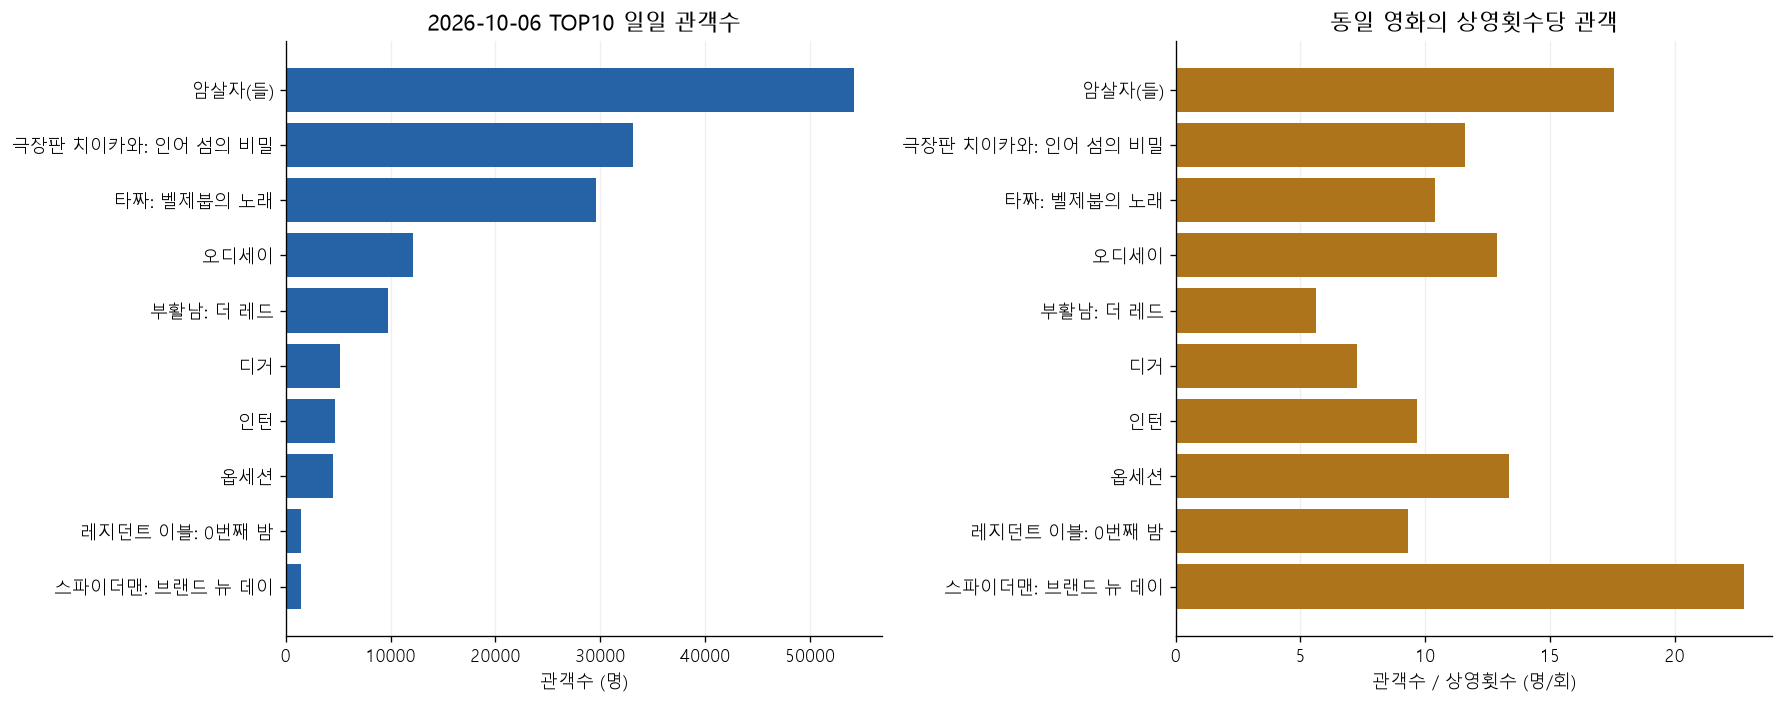

,rank,movieNm,audiCnt,scrnCnt,showCnt,audience_per_screen,audience_per_show
47,1,암살자(들),54177,993,3083,54.56,17.57
83,2,극장판 치이카와: 인어 섬의 비밀,33091,820,2855,40.35,11.59
61,3,타짜: 벨제붑의 노래,29569,969,2845,30.51,10.39
21,4,오디세이,12170,541,945,22.50,12.88
7,5,부활남: 더 레드,9798,671,1743,14.60,5.62
107,6,디거,5151,436,709,11.81,7.27
75,7,인턴,4718,359,487,13.14,9.69
122,8,옵세션,4471,262,335,17.06,13.35
103,9,레지던트 이블: 0번째 밤,1443,130,155,11.10,9.31
91,10,스파이더맨: 브랜드 뉴 데이,1435,58,63,24.74,22.78


**EDA 해석:** 2026-10-06 관객수 1위는 **암살자(들)**(54,177명), 상영횟수당 관객이 가장 높은 영화는 **스파이더맨: 브랜드 뉴 데이**(22.8명/회)입니다. 상영횟수당 관객은 좌석 수를 반영한 좌석점유율이 아닙니다.

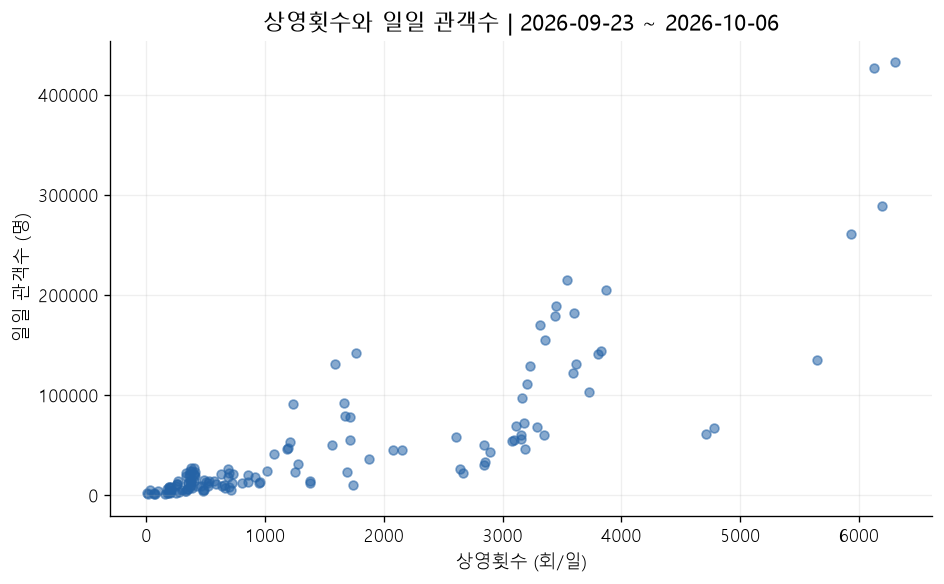

점 하나는 영화 1편의 하루입니다. 상영횟수와 관객수가 함께 늘어나는 관계는 확인할 수 있지만, 수요에 따라 상영횟수가 늘어날 수도 있어 인과 방향을 단정하지 않습니다.

In [7]:
# 7. EDA: 최신 일자 관객 규모와 상영 기회당 관객을 비교합니다.
latest = daily[daily.date==pd.Timestamp(END_DATE)].sort_values('audiCnt')
fig, axes = plt.subplots(1,2,figsize=(15,6))
axes[0].barh(latest.movieNm,latest.audiCnt,color=PALETTE[0])
axes[0].set(title=f'{END_DATE} TOP10 일일 관객수',xlabel='관객수 (명)')
axes[1].barh(latest.movieNm,latest.audience_per_show,color=PALETTE[1])
axes[1].set(title='동일 영화의 상영횟수당 관객',xlabel='관객수 / 상영횟수 (명/회)')
for ax in axes:
    ax.grid(axis='x',alpha=.2); ax.set_axisbelow(True)
save_plot('01_latest_audience_efficiency')
display(latest[['rank','movieNm','audiCnt','scrnCnt','showCnt','audience_per_screen','audience_per_show']].sort_values('rank').round(2))
biggest = latest.loc[latest.audiCnt.idxmax()]
efficient = latest.loc[latest.audience_per_show.idxmax()]
display(Markdown(f'**EDA 해석:** {END_DATE} 관객수 1위는 **{biggest.movieNm}**({biggest.audiCnt:,.0f}명), 상영횟수당 관객이 가장 높은 영화는 **{efficient.movieNm}**({efficient.audience_per_show:.1f}명/회)입니다. 상영횟수당 관객은 좌석 수를 반영한 좌석점유율이 아닙니다.'))
# 상영 규모와 관객의 관계를 일자별 영화 관측치로 확인합니다.
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(daily.showCnt,daily.audiCnt,alpha=.55,color=PALETTE[0],s=28)
ax.set(title=f'상영횟수와 일일 관객수 | {period_label}',xlabel='상영횟수 (회/일)',ylabel='일일 관객수 (명)')
ax.grid(alpha=.2); save_plot('02_screening_audience_relationship')
display(Markdown('점 하나는 영화 1편의 하루입니다. 상영횟수와 관객수가 함께 늘어나는 관계는 확인할 수 있지만, 수요에 따라 상영횟수가 늘어날 수도 있어 인과 방향을 단정하지 않습니다.'))

## 8. 질문 1 — 어떤 관객 반등이 관측됐는가?

위 그래프는 관객수 추이, 아래는 순위 추이입니다. 순위는 숫자가 작을수록 좋으므로 1위를 위쪽에 표시합니다. 주황색 배경은 공휴일, 회색 배경은 나머지 주말이며 TOP10에서 관측되지 않은 날은 선을 끊습니다. 설명용 5편은 관측 관객 합계 기준으로 선택하고, 후보 판정은 수집된 전체 영화에 적용합니다.

전주 같은 요일의 관객수와 순위가 함께 개선되고 회당 관객도 증가한 개봉 7일 이후의 관측을 표에 표시합니다. **기본 후보 결과를 본 뒤 반드시 10단계의 공휴일 민감도 결과까지 확인하세요.**

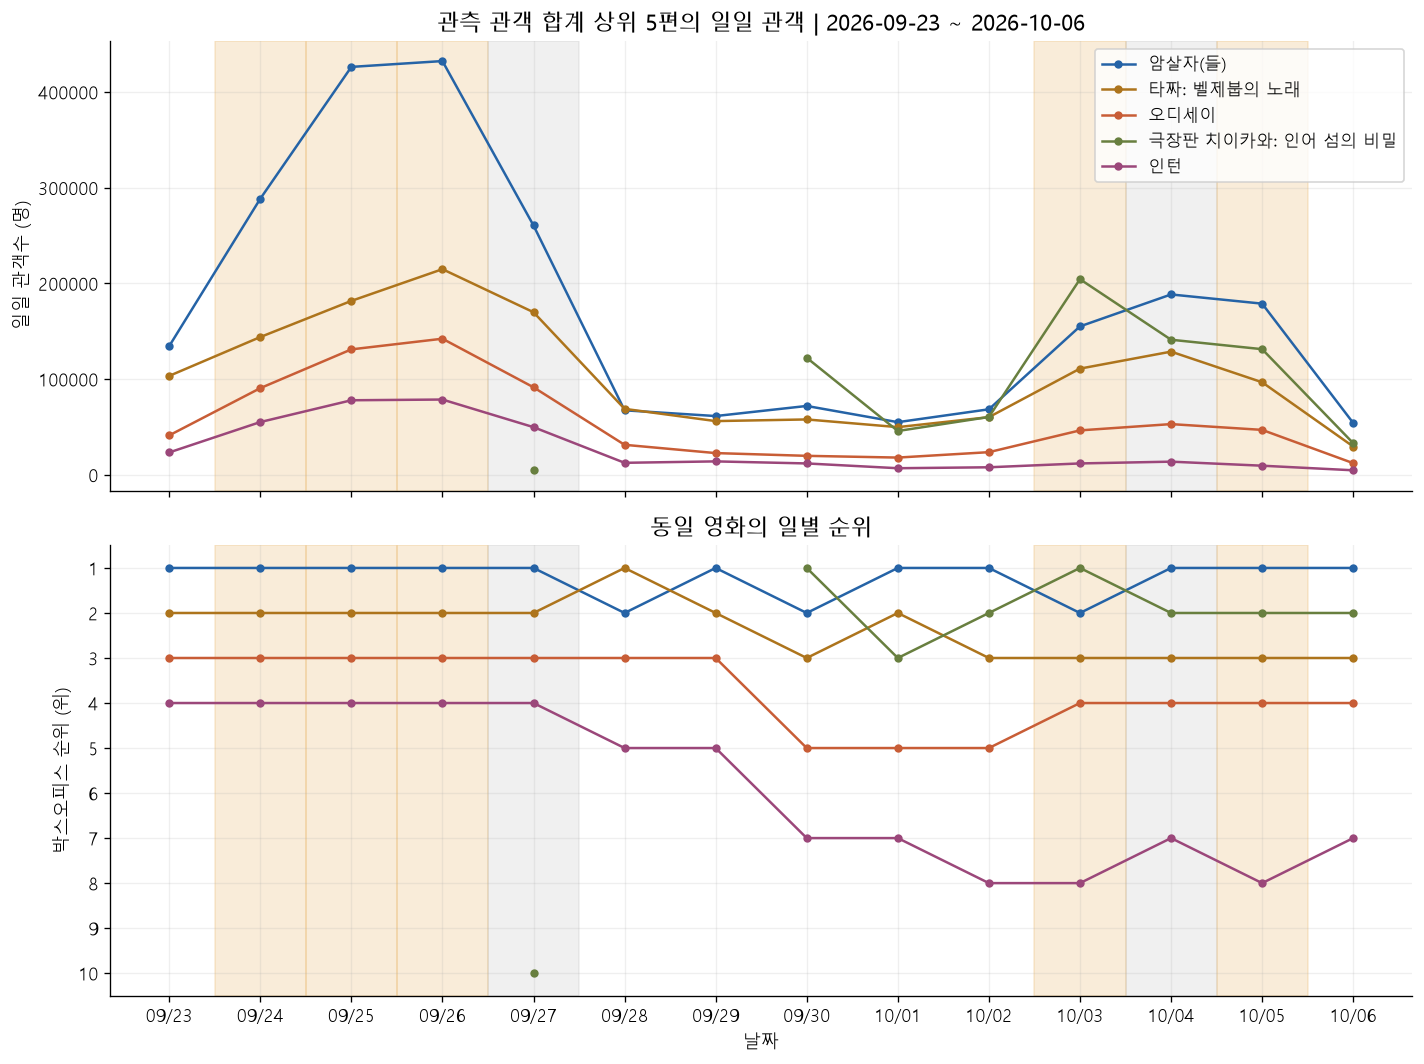

주황색 배경은 확인된 공휴일, 회색 배경은 나머지 주말입니다. 날짜를 모두 펼쳤으며 TOP10 밖의 날은 선이 끊깁니다. 표시한 5편은 관측 관객 합계 기준으로 고른 설명용 표본이고, 후보 판정은 17편 전체를 대상으로 합니다.

C:\Users\lcj10\AppData\Local\Temp\ipykernel_13644\563621512.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(candidates[cols].round(2))


,date,movieNm,rank,rank_wow_base,audiCnt,audiCnt_wow_base,audiCnt_growth_wow_pct,rank_gain_wow,audience_per_show_growth_wow_pct
46,2026-10-05,암살자(들),1,2.0,178856,67404.0,165.35,1.0,268.84


**질문 1 답변:** 2026-10-05 **암살자(들)**은 전주 같은 요일 대비 관객이 +165.3% 변했고 순위는 2위 → 1위로 개선됐습니다. 이는 관측된 역주행 후보이며 입소문 원인은 추가 증거가 필요합니다.

In [8]:
# 8. 질문 1: 관객·순위의 시계열과 전주 비교에서 역주행 후보 찾기
import matplotlib.dates as mdates
focus_ids = summary.sort_values('audience_in_observed_days',ascending=False).head(5).movieCd.tolist()
fig, axes = plt.subplots(2,1,figsize=(12,9),sharex=True)
for i, code in enumerate(focus_ids):
    film = daily[daily.movieCd==code].set_index('date').reindex(all_dates)
    name = daily.loc[daily.movieCd==code,'movieNm'].iloc[0]
    axes[0].plot(all_dates,film.audiCnt,color=PALETTE[i],marker='o',markersize=4,label=name)
    axes[1].plot(all_dates,film['rank'],color=PALETTE[i],marker='o',markersize=4)
axes[0].set(title=f'관측 관객 합계 상위 5편의 일일 관객 | {period_label}',ylabel='일일 관객수 (명)')
axes[0].legend(loc='upper right',fontsize=10)
axes[1].set(title='동일 영화의 일별 순위',ylabel='박스오피스 순위 (위)',xlabel='날짜')
axes[1].set_ylim(10.5,.5); axes[1].set_yticks(range(1,11))
axes[1].set_xticks(all_dates); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
for ax in axes:
    ax.grid(alpha=.2)
    shade_calendar(ax)
save_plot('03_audience_rank_timeseries')
display(Markdown('주황색 배경은 확인된 공휴일, 회색 배경은 나머지 주말입니다. 날짜를 모두 펼쳤으며 TOP10 밖의 날은 선이 끊깁니다. 표시한 5편은 관측 관객 합계 기준으로 고른 설명용 표본이고, 후보 판정은 17편 전체를 대상으로 합니다.'))
candidates = daily[daily.rebound_candidate].copy().sort_values('audiCnt_growth_wow_pct',ascending=False)
cols = ['date','movieNm','rank','rank_wow_base','audiCnt','audiCnt_wow_base','audiCnt_growth_wow_pct','rank_gain_wow','audience_per_show_growth_wow_pct']
candidates[cols].to_csv(OUT/'rebound_candidates.csv',index=False,encoding='utf-8-sig')
display(candidates[cols].round(2))
if len(candidates):
    for _, row in candidates.head(5).iterrows():
        display(Markdown(f'**질문 1 답변:** {row.date:%Y-%m-%d} **{row.movieNm}**은 전주 같은 요일 대비 관객이 {row.audiCnt_growth_wow_pct:+.1f}% 변했고 순위는 {row.rank_wow_base:.0f}위 → {row["rank"]:.0f}위로 개선됐습니다. 이는 관측된 역주행 후보이며 입소문 원인은 추가 증거가 필요합니다.'))
else:
    display(Markdown('**질문 1 답변:** 이번 기간에는 설정한 세 조건을 모두 충족하는 역주행 후보가 없습니다. 신작의 개봉 전후 증가나 순위만의 상승을 입소문으로 분류하지 않았습니다.'))

## 9. 질문 2 — 상영 기회와 관객 동원력은 어떻게 변했는가?

산점도의 가로축은 상영횟수 증감률, 세로축은 관객 증감률입니다. 대각선 위의 관측은 회당 관객이 개선된 경우입니다. 후보의 관객수·상영횟수·회당 관객을 첫 관측일=100인 지수로 바꿔 시계열도 비교합니다.

관객수 = 상영횟수 × 회당 관객이므로 성장률은 단순 합계가 아니라 (1+상영횟수 성장률) × (1+회당 관객 성장률) − 1입니다. 아래에서는 이 관계를 실제 후보 행으로 검증합니다. 공급과 수요가 함께 결정될 수 있어 이 계산은 인과적 기여도 추정이 아닙니다.

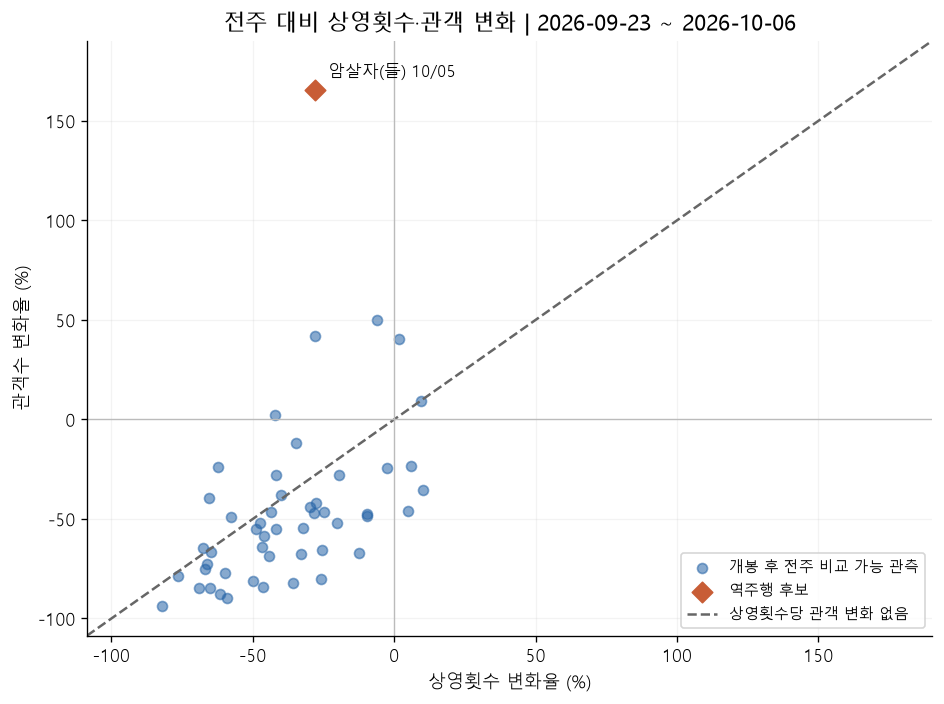

대각선 위쪽은 관객 증가율이 상영횟수 증가율보다 높아 상영횟수당 관객이 개선된 관측입니다. 같은 요일 비교로 평일·주말 차이를 줄였지만 공휴일 효과는 남아 있습니다.

**질문 2 답변:** 2026-10-05 **암살자(들)**은 전주 대비 상영횟수 -28.1%, 스크린수 -14.2%, 상영횟수당 관객 +268.8%입니다. 관객 증가를 상영 기회 확대만으로 설명할 수 없지만 입소문으로 확정할 수도 없습니다.

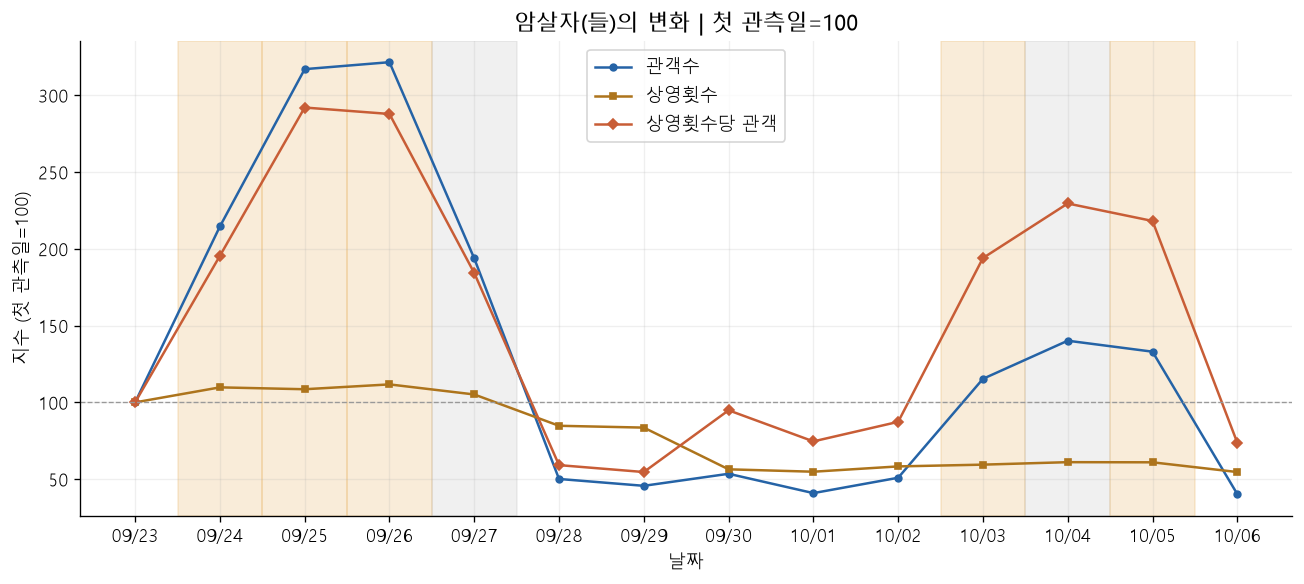

In [9]:
# 9. 질문 2: 상영횟수 확대인가, 상영횟수당 관객 증가인가?
# 관객수 = 상영횟수 × 상영횟수당 관객. 증감률은 단순 더하기가 아닌 곱셈 관계입니다.
comparable = daily[daily.post_open_wow].dropna(subset=['showCnt_growth_wow_pct','audience_per_show_growth_wow_pct']).copy()
fig, ax = plt.subplots(figsize=(8,6))
ax.scatter(comparable.showCnt_growth_wow_pct,comparable.audiCnt_growth_wow_pct,
           color=PALETTE[0],alpha=.55,label='개봉 후 전주 비교 가능 관측',s=36)
if len(candidates):
    ax.scatter(candidates.showCnt_growth_wow_pct,candidates.audiCnt_growth_wow_pct,
               marker='D',s=75,color=PALETTE[2],label='역주행 후보')
    for _, row in candidates.head(3).iterrows():
        ax.annotate(f'{row.movieNm} {row.date:%m/%d}',(row.showCnt_growth_wow_pct,row.audiCnt_growth_wow_pct),xytext=(8,8),textcoords='offset points',fontsize=10)
values = pd.concat([comparable.showCnt_growth_wow_pct,comparable.audiCnt_growth_wow_pct])
lo,hi = values.min()-15,values.max()+25
ax.plot([lo,hi],[lo,hi],color='#666666',linestyle='--',label='상영횟수당 관객 변화 없음')
ax.axvline(0,color='#bbbbbb',lw=.8); ax.axhline(0,color='#bbbbbb',lw=.8)
ax.set(xlim=(lo,hi),ylim=(lo,hi),title=f'전주 대비 상영횟수·관객 변화 | {period_label}',
       xlabel='상영횟수 변화율 (%)',ylabel='관객수 변화율 (%)')
ax.legend(fontsize=9); ax.grid(alpha=.15); save_plot('04_supply_demand_wow')
display(Markdown('대각선 위쪽은 관객 증가율이 상영횟수 증가율보다 높아 상영횟수당 관객이 개선된 관측입니다. 같은 요일 비교로 평일·주말 차이를 줄였지만 공휴일 효과는 남아 있습니다.'))
if len(candidates):
    focal = candidates.iloc[0]
    focal_id = focal.movieCd
    expected = (1+focal.showCnt_growth_wow_pct/100)*(1+focal.audience_per_show_growth_wow_pct/100)-1
    assert np.isclose(expected*100,focal.audiCnt_growth_wow_pct)
    display(Markdown(f'**질문 2 답변:** {focal.date:%Y-%m-%d} **{focal.movieNm}**은 전주 대비 상영횟수 {focal.showCnt_growth_wow_pct:+.1f}%, 스크린수 {focal.scrnCnt_growth_wow_pct:+.1f}%, 상영횟수당 관객 {focal.audience_per_show_growth_wow_pct:+.1f}%입니다. 관객 증가를 상영 기회 확대만으로 설명할 수 없지만 입소문으로 확정할 수도 없습니다.'))
else:
    focal_id = focus_ids[0]
    display(Markdown(f'**질문 2 답변:** 개봉 후 비교 가능한 {len(comparable)}개 관측 중 상영횟수당 관객이 증가한 관측은 {comparable.audience_per_show_growth_wow_pct.gt(0).sum()}개입니다. 역주행 후보와 관객 효율 개선은 구분해야 합니다.'))
film = daily[daily.movieCd==focal_id].set_index('date').reindex(all_dates)
base = film[['audiCnt','showCnt','audience_per_show']].dropna().iloc[0]
fig, ax = plt.subplots(figsize=(11,5))
for i,(column,label) in enumerate([('audiCnt','관객수'),('showCnt','상영횟수'),('audience_per_show','상영횟수당 관객')]):
    ax.plot(all_dates,film[column]/base[column]*100,label=label,color=PALETTE[i],marker=['o','s','D'][i],markersize=4)
ax.axhline(100,color='#999999',linestyle='--',lw=.8)
ax.set(title=f'{daily.loc[daily.movieCd==focal_id,"movieNm"].iloc[0]}의 변화 | 첫 관측일=100',ylabel='지수 (첫 관측일=100)',xlabel='날짜')
ax.set_xticks(all_dates); ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
shade_calendar(ax)
ax.grid(alpha=.2); ax.legend(); save_plot('05_candidate_index_timeseries')

## 10. 공휴일 민감도와 질문 3 — TOP10 지속성

같은 월요일이라도 공휴일과 일반 평일은 관객 패턴이 다를 수 있습니다. 공식 2026년 월력요항으로 이번 기간의 추석·개천절·대체공휴일을 확인한 뒤, 전주와 공휴일 여부가 다른 비교를 제외해 후보가 남는지 확인합니다. 이는 통계 모델로 공휴일 영향을 없앤 분석은 아닙니다. 비교할 날짜의 조건을 좁혔을 때 결과가 달라지는지 살펴보는 분석입니다.

공휴일 표의 확인 범위는 2026-09-23~2026-10-06입니다. 날짜를 바꾸면 확인 표를 갱신하세요. 범위 밖의 비교는 보수적 후보에서 제외합니다. 마지막 막대그래프는 이번 14일 TOP10 등장일수와 최장 연속 등장일수를 비교하며 전체 흥행 수명으로 해석하지 않습니다.

출처: [우주항공청 2026년 월력요항](https://www.kasa.go.kr/prog/bbsArticle/BBSMSTR_000000000010/view.do?bbsId=B000000000010&nttId=B000000001860Pe2zT3).

**표본과 민감도:** 전체→전주→개봉 후→공휴일 동일의 행수 흐름과 영화별 분모를 제시합니다. 서로 다른 공휴일 유형이 같은 수요를 보장하지 않습니다. 여러 관측일과 정확한 연속 2일은 구별합니다. 이 기준은 첫 결과를 확인한 뒤 추가했습니다. 사전 등록한 분석은 아닙니다. 특정 영화를 후보에 넣거나 빼는 데 유리한 기준 하나를 고르지 않고, 비교한 설정을 모두 기록합니다.

**지속성:** 개봉 이후 TOP10 등장일수 ÷ 개봉 이후 관측 가능한 달력 일수 × 100을 함께 제시합니다. 개봉 전 등장일은 별도로 셉니다. 짧은 신작의 100%를 장기 유지력으로 해석하지 않습니다.

**외부 사건:** 사건일·기사일·주최자·제공량·실제 사용량·시행/취소·근거 수준을 구분합니다. 날짜 표시만으로 원인이라고 단정하지 않고 암살자(들) 포함/제외 표도 제공합니다. 다른 영화의 행사 자료를 찾지 못해도 행사가 없었다고 처리하지 않습니다.


,date,movieNm,holiday_name,holiday_mismatch_wow,holiday_robust_candidate
46,2026-10-05,암살자(들),개천절 대체공휴일,True,False


**민감도 분석 결과:** 기본 후보는 1편·1일, 공휴일 여부가 다른 비교를 제외한 후보는 0편·0일입니다. [공식 월력요항](https://www.kasa.go.kr/prog/bbsArticle/BBSMSTR_000000000010/view.do?bbsId=B000000000010&nttId=B000000001860Pe2zT3)에 따르면 10월 5일은 개천절 대체공휴일입니다. 동일 요일 비교만으로 공휴일 효과를 없앨 수 없으므로 이번 후보를 입소문 영화로 확정하지 않습니다.

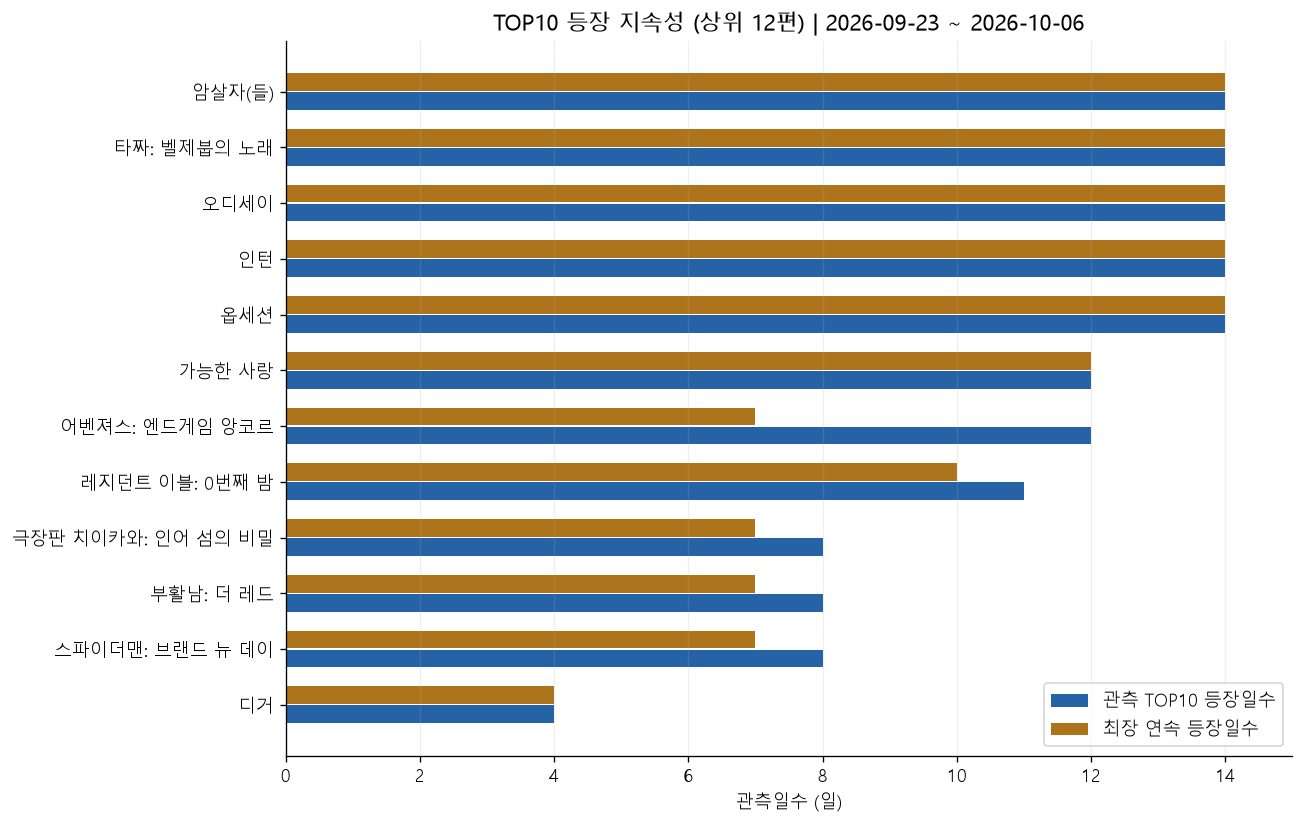

**질문 3 답변:** 14일 내내 TOP10에서 관측된 영화는 5편: 오디세이, 암살자(들), 타짜: 벨제붑의 노래, 인턴, 옵세션입니다. 기간 시작 전과 종료 후는 관측하지 않았으므로 이 일수를 전체 흥행 수명으로 해석하지 않습니다.

,stage,rows
0,전체 영화-일,140
1,정확한 전주 비교,52
2,개봉 후 비교,50
3,공휴일 여부 동일 비교,28


,movieCd,movieNm,observed_days,post_open_comparable_days,holiday_comparable_days,audience_rebound_days,efficiency_improved_days,rank_improved_days,holiday_excluded_days
0,20224573,부활남: 더 레드,8,0,0,0,0,0,0
1,20250654,오디세이,14,7,4,1,1,0,3
2,20254904,가능한 사랑,12,5,3,1,0,0,2
3,20255033,암살자(들),14,7,4,1,3,1,3
4,20256161,타짜: 벨제붑의 노래,14,7,4,1,1,0,3
5,20256308,인턴,14,7,4,0,2,0,3
6,20261807,극장판 치이카와: 인어 섬의 비밀,8,0,0,0,0,0,0
7,20262770,스파이더맨: 브랜드 뉴 데이,8,1,1,0,1,0,0
8,20262961,이방인,1,0,0,0,0,0,0
9,20263870,레지던트 이블: 0번째 밤,11,4,2,0,1,0,2


C:\Users\lcj10\AppData\Local\Temp\ipykernel_13644\2694431327.py:54: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(daily.loc[daily.audience_rebound,['date','movieNm','audiCnt_growth_wow_pct','audience_per_show_growth_wow_pct','rank_gain_wow','rebound_candidate','holiday_comparable']].round(2))


,date,movieNm,audiCnt_growth_wow_pct,audience_per_show_growth_wow_pct,rank_gain_wow,rebound_candidate,holiday_comparable
20,2026-10-05,오디세이,49.73,59.64,-1.0,False,False
33,2026-10-04,가능한 사랑,9.43,-0.02,-1.0,False,True
46,2026-10-05,암살자(들),165.35,268.84,1.0,True,False
60,2026-10-05,타짜: 벨제붑의 노래,40.34,38.08,-2.0,False,False
121,2026-10-05,옵세션,2.06,76.46,-1.0,False,False
138,2026-10-05,어벤져스: 엔드게임 앙코르,41.77,97.22,-2.0,False,False


,scope,rule,threshold_pct_strictly_above,minimum_consecutive_days,eligible_rows,selected_movie_days,selected_films
0,개봉 후 전주 비교,관객,0,1,50,6,6
1,개봉 후 전주 비교,관객,0,2,50,0,0
2,개봉 후 전주 비교,회당 관객,0,1,50,12,8
3,개봉 후 전주 비교,회당 관객,0,2,50,5,2
4,개봉 후 전주 비교,관객+회당 관객,0,1,50,5,5
5,개봉 후 전주 비교,관객+회당 관객,0,2,50,0,0
6,개봉 후 전주 비교,관객+회당 관객+순위,0,1,50,1,1
7,개봉 후 전주 비교,관객+회당 관객+순위,0,2,50,0,0
8,개봉 후 전주 비교,관객,10,1,50,4,4
9,개봉 후 전주 비교,관객,10,2,50,0,0


0·10·20%와 연속 1·2일은 탐색 기준입니다. 1위 유지 영화는 순위 개선이 불가능합니다. 관객 반등과 엄격한 결합 후보를 구별하며, 여러 날 관측된 것을 연속 반등으로 바꾸지 않습니다. 공휴일 여부가 같아도 공휴일 유형·개봉 연령은 같지 않습니다.

,sample,eligible_rows,audience_rebound_days,strict_candidate_days,holiday_candidate_days
0,전체,50,6,1,0
1,암살자(들) 제외,43,5,0,0


C:\Users\lcj10\AppData\Local\Temp\ipykernel_13644\2694431327.py:97: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  persistence=pd.DataFrame(persistence);save_csv(persistence,'post_open_persistence.csv');display(persistence.round(1))


,movieCd,movieNm,openDt,pre_open_top10_days,post_open_top10_days,post_open_available_calendar_days,post_open_top10_rate_pct,age_at_period_end_days
0,20224573,부활남: 더 레드,2026-09-30,1,7,7,100.0,6
1,20250654,오디세이,2026-08-05,0,14,14,100.0,62
2,20254904,가능한 사랑,2026-09-23,0,12,14,85.7,13
3,20255033,암살자(들),2026-09-23,0,14,14,100.0,13
4,20256161,타짜: 벨제붑의 노래,2026-09-23,0,14,14,100.0,13
5,20256308,인턴,2026-09-16,0,14,14,100.0,20
6,20261807,극장판 치이카와: 인어 섬의 비밀,2026-09-30,1,7,7,100.0,6
7,20262770,스파이더맨: 브랜드 뉴 데이,2026-07-29,0,8,14,57.1,69
8,20262961,이방인,2026-09-30,0,1,7,14.3,6
9,20263870,레지던트 이블: 0번째 밤,2026-09-17,0,11,14,78.6,19


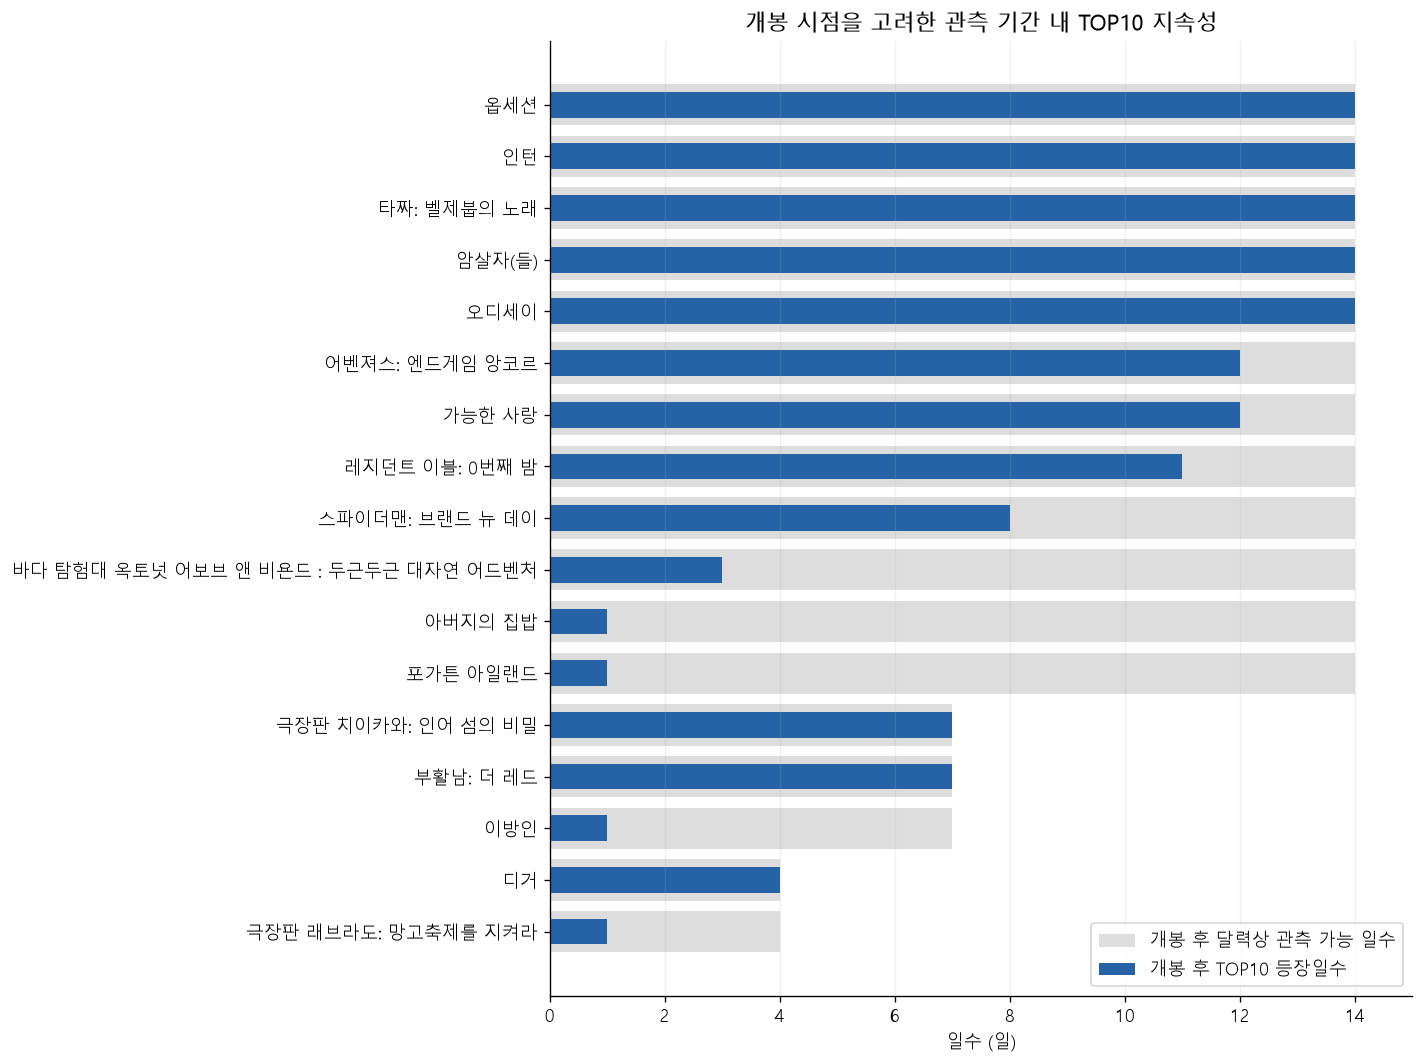

분모는 개봉일과 분석 시작일 중 늦은 날짜부터 종료일까지입니다. 짧은 신작의 100%는 오래된 영화의 100%와 같은 유지력을 뜻하지 않습니다. TOP10 미관측일은 관객 0이 아니며 전체 흥행 수명도 알 수 없습니다. 동일 개봉 연령 비교와 28~56일 확장은 후속 자료가 필요합니다.

,event_date,article_date,movieNm,host,event,provided_tickets,status,evidence_limit,source_url,actual_used_tickets,primary_records_available,evidence_level
0,2026-09-28,2026-10-02,암살자(들),미래에셋증권,기관 관람권 제공,122.0,시행 보도,기관 제출자료를 인용한 기사; 원본 미확인,https://www.biztribune.co.kr/news/articleView....,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인
1,2026-09-28,2026-09-29,암살자(들),박지원 의원,SNS 관람 독려,NaN,발언 보도,무료 관람권 배포 증거 아님,https://www.segye.com/newsView/20260929502920,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인
2,2026-10-01,2026-10-02,암살자(들),부산 관련 지원 사업,무료 시사회 취소,NaN,취소 보도,시행일 대신 취소일 표시; 정당 반론 별도,https://www.fnnews.com/news/202610021649434222,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인
3,2026-10-14,2026-09-30,암살자(들),제대군인지원센터,120명 계획 관람작 변경,NaN,변경 보도,계획 인원 120은 실관객 아님; 관측 기간 밖,https://v.daum.net/v/20260930193154199,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인
4,NaN,2026-09-30,암살자(들),한국교직원공제회,500명 계획 관람작 변경,NaN,변경 보도,계획 500; 실제 사용량·시행일 미확인,https://v.daum.net/v/20260930193154199,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인
5,2026-10-01,2026-10-04,암살자(들),네이버,관람평 어뷰징 의심 수사 의뢰,NaN,수사 의뢰 보도,행위 주체·의도·책임 확정 아님; Cine21 전문가 평점과 별개,https://www4.edaily.co.kr/News/Read?mediaCodeN...,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인
6,NaN,2026-10-01,오디세이,미래에셋증권,다른 영화 단체관람도 진행했다는 설명,NaN,회사 설명,실제 날짜·규모 독립 확인 없음; 회사 설명이 유일 근거,https://www.ytn.co.kr/_ln/0103_202610012311592780,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인
7,NaN,NaN,암살자(들),하이브미디어코프,할인·회원 시사회 공개 안내,NaN,공개 홍보 페이지,수량·사용 날짜 미확인,https://litt.ly/hivemedia_corp,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인
8,NaN,2026-10-06,암살자(들),민주당 부산시당,기존 지원 사업이라는 반론,NaN,정당 설명,발언 자체와 사실의 입증을 구분,https://www.kookje.co.kr/news2011/asp/newsbody...,NaN,False,보도/발언/공개안내 존재 확인; 실제 사용량 미확인


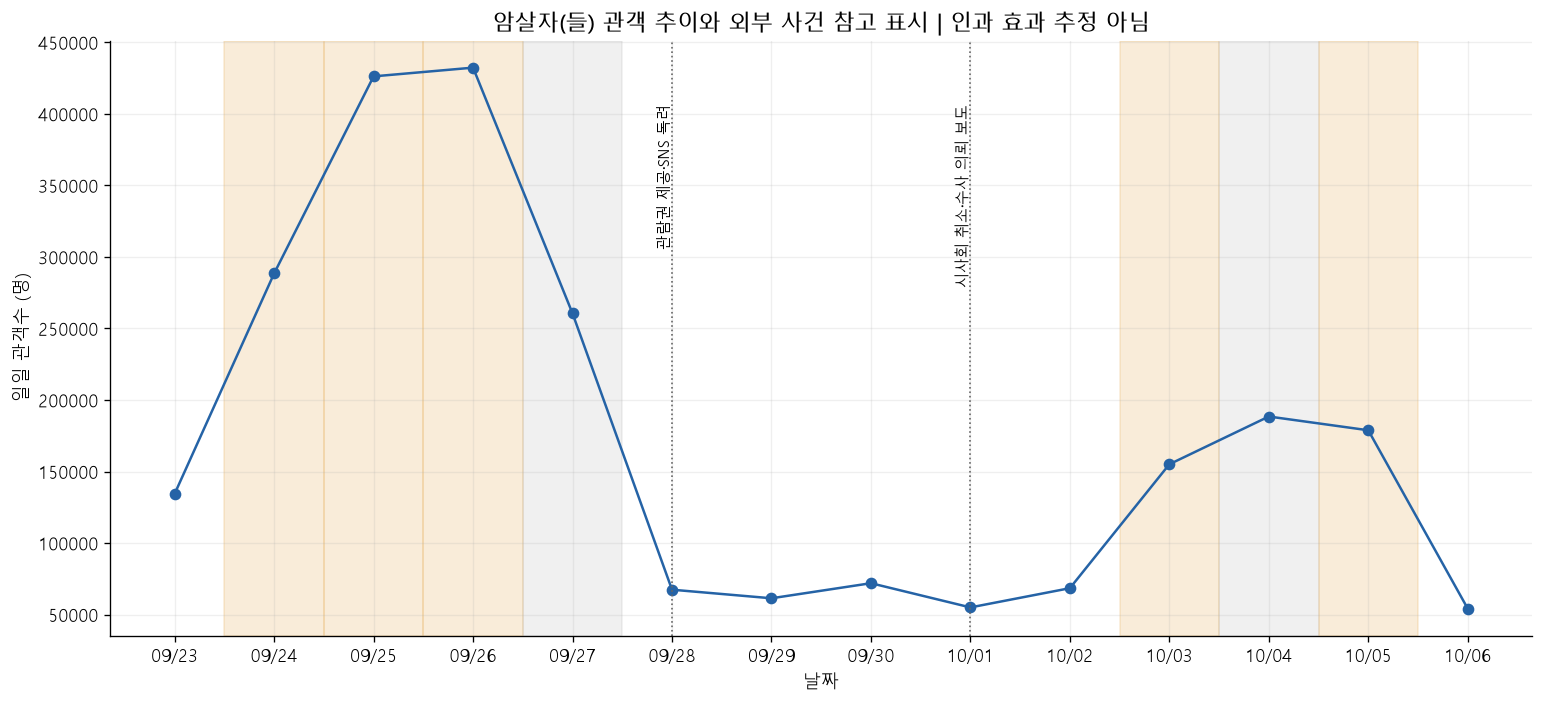

122매 제공은 사용량·전국 규모가 아닙니다. 취소·변경된 행사 계획 인원을 실관객으로 더하지 않습니다. 9/28 지역 행사와 10/5 증가분을 직접 연결할 수 없습니다. 다른 영화의 외부 요인이 미확인인 상황에서 상대적 특수성도 확정할 수 없습니다. 평균 매출/관객은 가격 구성 탐색값이며 무료표 식별값이 아닙니다.

In [10]:
# 10. 민감도 분석: 공휴일 여부가 다른 전주 비교를 제외하면 결론이 유지되는가?
# 아래 공휴일은 이번 관측 범위에 대해 공식 2026년 월력요항으로 확인했습니다.
# 다른 기간으로 실행할 때는 HOLIDAY_CHECK_START/END와 공휴일 표를 갱신해야 합니다.
HOLIDAY_SOURCE = 'https://www.kasa.go.kr/prog/bbsArticle/BBSMSTR_000000000010/view.do?bbsId=B000000000010&nttId=B000000001860Pe2zT3'
HOLIDAY_CHECK_START, HOLIDAY_CHECK_END = pd.Timestamp('2026-09-23'), pd.Timestamp('2026-10-06')
holiday_names = {'2026-09-24':'추석 연휴','2026-09-25':'추석','2026-09-26':'추석 연휴',
                 '2026-10-03':'개천절','2026-10-05':'개천절 대체공휴일'}
holiday_dates = pd.to_datetime(list(holiday_names))
daily['holiday_name'] = daily.date.dt.strftime('%Y-%m-%d').map(holiday_names)
daily['is_holiday'] = daily.date.isin(holiday_dates)
base_date = daily.date-pd.Timedelta(days=7)
daily['holiday_calendar_verified'] = daily.date.between(HOLIDAY_CHECK_START,HOLIDAY_CHECK_END) & base_date.between(HOLIDAY_CHECK_START,HOLIDAY_CHECK_END)
daily['holiday_mismatch_wow'] = daily.is_holiday.ne(base_date.isin(holiday_dates))
daily['holiday_robust_candidate'] = daily.rebound_candidate & daily.holiday_calendar_verified & ~daily.holiday_mismatch_wow
candidates = daily[daily.rebound_candidate].copy()
robust_candidates = daily[daily.holiday_robust_candidate].copy()
display(candidates[['date','movieNm','holiday_name','holiday_mismatch_wow','holiday_robust_candidate']])
display(Markdown(f'**민감도 분석 결과:** 기본 후보는 {candidates.movieCd.nunique()}편·{len(candidates)}일, 공휴일 여부가 다른 비교를 제외한 후보는 {robust_candidates.movieCd.nunique()}편·{len(robust_candidates)}일입니다. [공식 월력요항]({HOLIDAY_SOURCE})에 따르면 10월 5일은 개천절 대체공휴일입니다. 동일 요일 비교만으로 공휴일 효과를 없앨 수 없으므로 이번 후보를 입소문 영화로 확정하지 않습니다.'))
if not daily.holiday_calendar_verified[daily.post_open_wow].all():
    print('주의: 변경된 기간의 공휴일을 확인하고 공휴일 표를 갱신하세요. 미확인 비교는 보수적 후보에서 제외됩니다.')
daily.to_csv(OUT/'movie_daily_features.csv',index=False,encoding='utf-8-sig')
candidates.to_csv(OUT/'rebound_candidates.csv',index=False,encoding='utf-8-sig')
robust_candidates.to_csv(OUT/'holiday_robust_candidates.csv',index=False,encoding='utf-8-sig')

# 질문 3. 유지일수와 최장 연속 등장일수를 함께 비교합니다.
fig, ax = plt.subplots(figsize=(11,7))
stay = summary.sort_values(['top10_days','audience_in_observed_days']).tail(12)
y = np.arange(len(stay))
ax.barh(y-.17,stay.top10_days,height=.32,color=PALETTE[0],label='관측 TOP10 등장일수')
ax.barh(y+.17,stay.longest_top10_streak,height=.32,color=PALETTE[1],label='최장 연속 등장일수')
ax.set_yticks(y,stay.movieNm)
ax.set(title=f'TOP10 등장 지속성 (상위 12편) | {period_label}',xlabel='관측일수 (일)',xlim=(0,15))
ax.set_xticks(range(0,15,2)); ax.legend(loc='lower right'); ax.grid(axis='x',alpha=.2)
save_plot('06_top10_persistence')
full_period = summary[summary.top10_days==14]
display(Markdown(f'**질문 3 답변:** 14일 내내 TOP10에서 관측된 영화는 {len(full_period)}편: '+', '.join(full_period.movieNm)+'입니다. 기간 시작 전과 종료 후는 관측하지 않았으므로 이 일수를 전체 흥행 수명으로 해석하지 않습니다.'))
EVENT_ROWS = [('2026-09-28', '2026-10-02', '암살자(들)', '미래에셋증권', '기관 관람권 제공', 122, '시행 보도', '기관 제출자료를 인용한 기사; 원본 미확인', 'https://www.biztribune.co.kr/news/articleView.html?idxno=359982'), ('2026-09-28', '2026-09-29', '암살자(들)', '박지원 의원', 'SNS 관람 독려', None, '발언 보도', '무료 관람권 배포 증거 아님', 'https://www.segye.com/newsView/20260929502920'), ('2026-10-01', '2026-10-02', '암살자(들)', '부산 관련 지원 사업', '무료 시사회 취소', None, '취소 보도', '시행일 대신 취소일 표시; 정당 반론 별도', 'https://www.fnnews.com/news/202610021649434222'), ('2026-10-14', '2026-09-30', '암살자(들)', '제대군인지원센터', '120명 계획 관람작 변경', None, '변경 보도', '계획 인원 120은 실관객 아님; 관측 기간 밖', 'https://v.daum.net/v/20260930193154199'), (None, '2026-09-30', '암살자(들)', '한국교직원공제회', '500명 계획 관람작 변경', None, '변경 보도', '계획 500; 실제 사용량·시행일 미확인', 'https://v.daum.net/v/20260930193154199'), ('2026-10-01', '2026-10-04', '암살자(들)', '네이버', '관람평 어뷰징 의심 수사 의뢰', None, '수사 의뢰 보도', '행위 주체·의도·책임 확정 아님; Cine21 전문가 평점과 별개', 'https://www4.edaily.co.kr/News/Read?mediaCodeNo=257&newsId=01643286645609640'), (None, '2026-10-01', '오디세이', '미래에셋증권', '다른 영화 단체관람도 진행했다는 설명', None, '회사 설명', '실제 날짜·규모 독립 확인 없음; 회사 설명이 유일 근거', 'https://www.ytn.co.kr/_ln/0103_202610012311592780'), (None, None, '암살자(들)', '하이브미디어코프', '할인·회원 시사회 공개 안내', None, '공개 홍보 페이지', '수량·사용 날짜 미확인', 'https://litt.ly/hivemedia_corp'), (None, '2026-10-06', '암살자(들)', '민주당 부산시당', '기존 지원 사업이라는 반론', None, '정당 설명', '발언 자체와 사실의 입증을 구분', 'https://www.kookje.co.kr/news2011/asp/newsbody.asp?code=00&key=20261006.99099001391')]

# 지표를 별도로 보고, 순위 천장과 기준의 민감도를 확인합니다.
eligible = daily.post_open_wow
daily['audience_rebound'] = eligible & daily.audiCnt_growth_wow_pct.gt(0)
daily['efficiency_improved'] = eligible & daily.audience_per_show_growth_wow_pct.gt(0)
daily['rank_improved'] = eligible & daily.rank_gain_wow.gt(0)
daily['holiday_comparable'] = eligible & daily.holiday_calendar_verified & ~daily.holiday_mismatch_wow
flow = pd.DataFrame({'stage':['전체 영화-일','정확한 전주 비교','개봉 후 비교','공휴일 여부 동일 비교'],
                     'rows':[len(daily),daily.audiCnt_growth_wow_pct.notna().sum(),eligible.sum(),daily.holiday_comparable.sum()]})
save_csv(flow,'comparison_flow.csv');display(flow)
denominators = daily.groupby(['movieCd','movieNm'],as_index=False).agg(
    observed_days=('date','nunique'),post_open_comparable_days=('post_open_wow','sum'),
    holiday_comparable_days=('holiday_comparable','sum'),audience_rebound_days=('audience_rebound','sum'),
    efficiency_improved_days=('efficiency_improved','sum'),rank_improved_days=('rank_improved','sum'))
denominators['holiday_excluded_days']=denominators.post_open_comparable_days-denominators.holiday_comparable_days
save_csv(denominators,'movie_comparison_denominators.csv');display(denominators)
display(daily.loc[daily.audience_rebound,['date','movieNm','audiCnt_growth_wow_pct','audience_per_show_growth_wow_pct','rank_gain_wow','rebound_candidate','holiday_comparable']].round(2))
def consecutive_flags(mask):
    # 정확한 달력 날짜가 연속인 True만 같은 반등 구간으로 셉니다.
    sizes=pd.Series(0,index=daily.index,dtype=int)
    for _, group in daily.groupby('movieCd'):
        g=group.sort_values('date');m=mask.loc[g.index]
        block=(g.date.diff().dt.days.ne(1)|~m|~m.shift(fill_value=False)).cumsum()
        sizes.loc[g.index]=m.groupby(block).transform('sum').where(m,0).astype(int)
    return sizes
tests=[]
for scope, allowed in [('개봉 후 전주 비교',eligible),('공휴일 여부 동일',daily.holiday_comparable)]:
    for threshold in [0,10,20]:
        for rule in ['관객','회당 관객','관객+회당 관객','관객+회당 관객+순위']:
            mask=allowed.copy()
            if '관객' in rule and rule!='회당 관객':mask &= daily.audiCnt_growth_wow_pct.gt(threshold)
            if '회당 관객' in rule:mask &= daily.audience_per_show_growth_wow_pct.gt(threshold)
            if '순위' in rule:mask &= daily.rank_gain_wow.gt(0)
            runs=consecutive_flags(mask)
            for days in [1,2]:
                selected=mask & runs.ge(days)
                tests.append({'scope':scope,'rule':rule,'threshold_pct_strictly_above':threshold,
                              'minimum_consecutive_days':days,'eligible_rows':int(allowed.sum()),
                              'selected_movie_days':int(selected.sum()),'selected_films':daily.loc[selected,'movieCd'].nunique()})
sensitivity=pd.DataFrame(tests);save_csv(sensitivity,'candidate_sensitivity.csv');display(sensitivity)
display(Markdown('0·10·20%와 연속 1·2일은 탐색 기준입니다. 1위 유지 영화는 순위 개선이 불가능합니다. 관객 반등과 엄격한 결합 후보를 구별하며, 여러 날 관측된 것을 연속 반등으로 바꾸지 않습니다. 공휴일 여부가 같아도 공휴일 유형·개봉 연령은 같지 않습니다.'))
# 특정 영화 포함/제외: 매출·관객에서 티켓 매수를 차감하지 않습니다.
exclusions=[]
for label, keep in [('전체',pd.Series(True,index=daily.index)),('암살자(들) 제외',daily.movieNm.ne('암살자(들)'))]:
    exclusions.append({'sample':label,'eligible_rows':int((keep&eligible).sum()),
                       'audience_rebound_days':int((keep&daily.audience_rebound).sum()),
                       'strict_candidate_days':int((keep&daily.rebound_candidate).sum()),
                       'holiday_candidate_days':int((keep&daily.holiday_robust_candidate).sum())})
exclusion_comparison=pd.DataFrame(exclusions);save_csv(exclusion_comparison,'target_exclusion_comparison.csv');display(exclusion_comparison)
# 개봉 후 관측 가능한 달력 일수가 짧은 신작을 분리합니다.
persistence=[]
for (code,name), g in daily.groupby(['movieCd','movieNm']):
    opened=g.openDt.iloc[0]
    available=max(0,(pd.Timestamp(END_DATE)-max(opened,pd.Timestamp(START_DATE))).days+1) if pd.notna(opened) else np.nan
    post=g.date.ge(opened)
    persistence.append({'movieCd':code,'movieNm':name,'openDt':opened,'pre_open_top10_days':int((~post).sum()),
                        'post_open_top10_days':int(post.sum()),'post_open_available_calendar_days':available,
                        'post_open_top10_rate_pct':post.sum()/available*100 if available else np.nan,
                        'age_at_period_end_days':(pd.Timestamp(END_DATE)-opened).days})
persistence=pd.DataFrame(persistence);save_csv(persistence,'post_open_persistence.csv');display(persistence.round(1))
fig,ax=plt.subplots(figsize=(12,9));p=persistence.sort_values(['post_open_available_calendar_days','post_open_top10_days'])
y=np.arange(len(p));ax.barh(y,p.post_open_available_calendar_days,color='#dddddd',label='개봉 후 달력상 관측 가능 일수')
ax.barh(y,p.post_open_top10_days,color=PALETTE[0],height=.5,label='개봉 후 TOP10 등장일수')
ax.set_yticks(y,p.movieNm);ax.set(xlabel='일수 (일)',title='개봉 시점을 고려한 관측 기간 내 TOP10 지속성',xlim=(0,15));ax.legend(loc='lower right')
ax.grid(axis='x',alpha=.2);save_plot('08_post_open_persistence')
display(Markdown('분모는 개봉일과 분석 시작일 중 늦은 날짜부터 종료일까지입니다. 짧은 신작의 100%는 오래된 영화의 100%와 같은 유지력을 뜻하지 않습니다. TOP10 미관측일은 관객 0이 아니며 전체 흥행 수명도 알 수 없습니다. 동일 개봉 연령 비교와 28~56일 확장은 후속 자료가 필요합니다.'))
events=pd.DataFrame(EVENT_ROWS,columns=['event_date','article_date','movieNm','host','event','provided_tickets','status','evidence_limit','source_url'])
events['actual_used_tickets']=np.nan;events['primary_records_available']=False
events['evidence_level']='보도/발언/공개안내 존재 확인; 실제 사용량 미확인'
save_csv(events,'external_events.csv');display(events)
coverage=daily[['movieCd','movieNm']].drop_duplicates().copy()
coverage['external_evidence_status']=coverage.movieNm.map({'암살자(들)':'사건 보도 및 공개 홍보 검토','오디세이':'회사 설명에 언급; 날짜·수량 독립 미확인'}).fillna('이번 검토에서 동일 수준의 사건 자료 미확보; 프로모션 없음 뜻 아님')
save_csv(coverage,'external_evidence_coverage.csv')
fig,ax=plt.subplots(figsize=(13,6));f=daily[daily.movieNm=='암살자(들)'].set_index('date').reindex(all_dates)
ax.plot(all_dates,f.audiCnt,marker='o',color=PALETTE[0]);shade_calendar(ax)
for d,label in [('2026-09-28','관람권 제공·SNS 독려'),('2026-10-01','시사회 취소·수사 의뢰 보도')]:
    day=pd.Timestamp(d)
    if day in all_dates:
        ax.axvline(day,color='#666666',linestyle=':',lw=1)
        ax.text(day,ax.get_ylim()[1]*.90,label,rotation=90,fontsize=9,va='top',ha='right')
ax.set(title='암살자(들) 관객 추이와 외부 사건 참고 표시 | 인과 효과 추정 아님',ylabel='일일 관객수 (명)',xlabel='날짜')
ax.set_xticks(all_dates);ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'));ax.grid(alpha=.2);save_plot('09_external_events_timeseries')
daily['average_sales_per_audience']=daily.salesAmt/daily.audiCnt.replace(0,np.nan)
display(Markdown('122매 제공은 사용량·전국 규모가 아닙니다. 취소·변경된 행사 계획 인원을 실관객으로 더하지 않습니다. 9/28 지역 행사와 10/5 증가분을 직접 연결할 수 없습니다. 다른 영화의 외부 요인이 미확인인 상황에서 상대적 특수성도 확정할 수 없습니다. 평균 매출/관객은 가격 구성 탐색값이며 무료표 식별값이 아닙니다.'))
save_csv(daily,'movie_daily_features.csv')


## 11. 보조 EDA — 영화 특성과 전문가 평점

영화별 관측 관객 합계 ÷ 관측 상영횟수 합계로 가중된 회당 관객을 계산합니다. 전문가 별점이 있는 영화만 산점도에 표시하고 장르·등급·관측일수도 함께 봅니다. 일별 비율의 단순 평균을 쓰지 않아 상영횟수가 적은 날이 과도하게 반영되지 않도록 했습니다.

현재 TOP10 중심의 작은 선택 표본이며 영화별 개봉 연령과 관측 기간이 다릅니다. 이 결과로 전체 영화의 평점·장르·등급이 흥행에 미치는 영향을 판단할 수는 없습니다. 전문가 20자평은 별도 CSV에 보존하며 텍스트 모델 분석은 이 노트북의 필수 범위에 포함하지 않습니다.

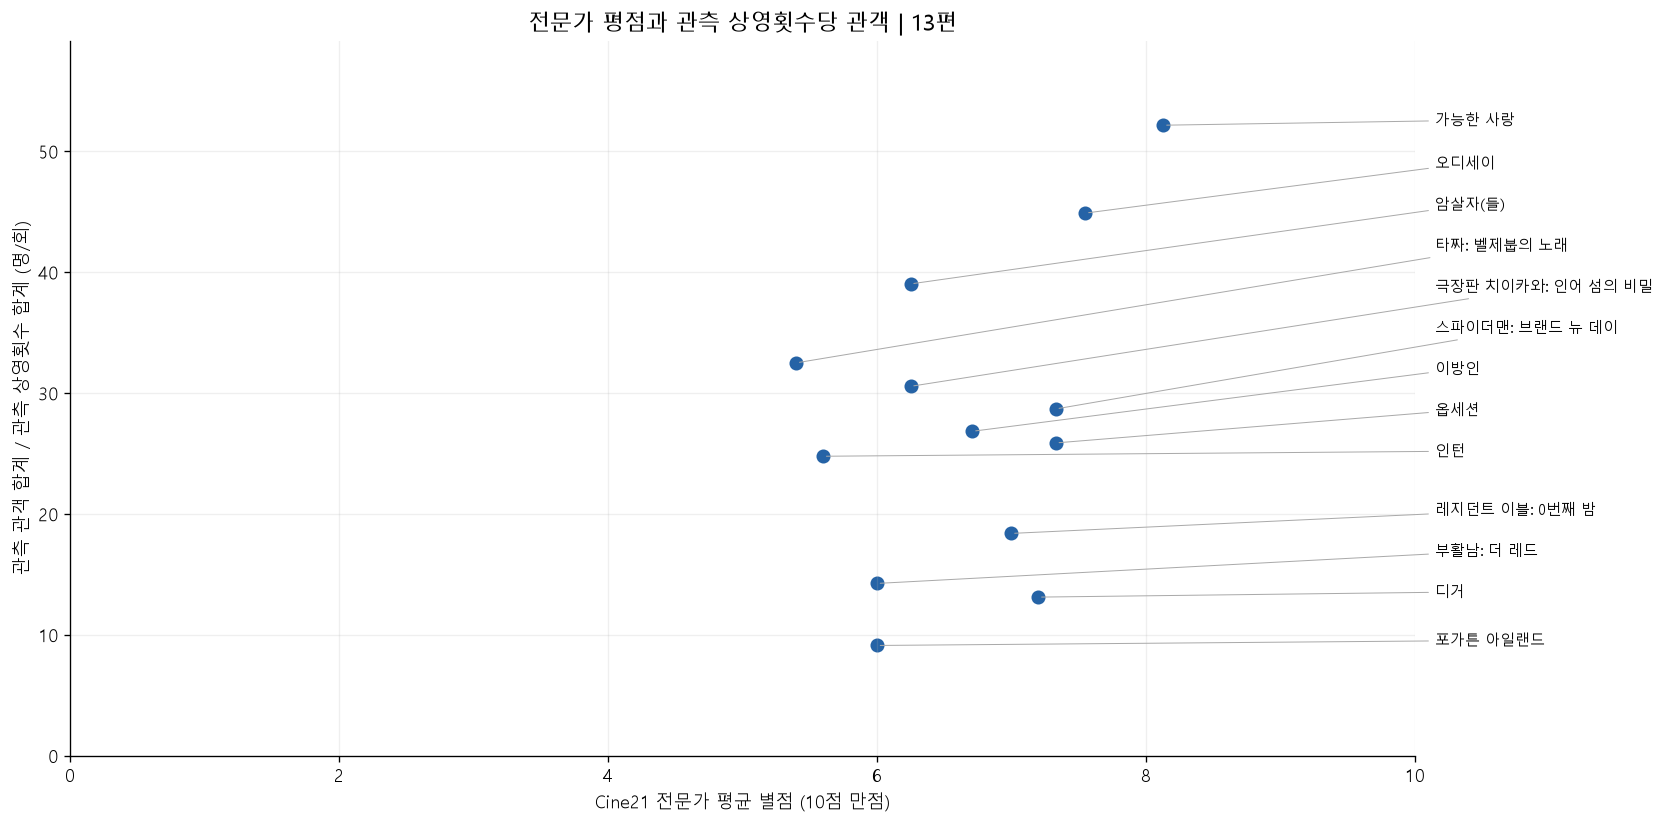

,movieNm,genre,rating,expert_score,observed_days,weighted_audience_per_show
0,부활남: 더 레드,액션,15세이상관람가,6.00,8,14.25
1,오디세이,"액션, 모험, 드라마",15세이상관람가,7.55,14,44.89
2,가능한 사랑,드라마,청소년 관람불가,8.13,12,52.16
3,암살자(들),"범죄, 드라마",12세이상관람가,6.25,14,39.03
4,타짜: 벨제붑의 노래,"드라마, 범죄",청소년 관람불가,5.40,14,32.50
5,인턴,드라마,12세이상관람가,5.60,14,24.77
6,극장판 치이카와: 인어 섬의 비밀,애니메이션,전체 관람가,6.25,8,30.55
7,스파이더맨: 브랜드 뉴 데이,"판타지, 어드벤처, 액션",12세이상관람가,7.33,8,28.68
8,이방인,드라마,15세이상관람가,6.71,1,26.84
9,레지던트 이블: 0번째 밤,"SF, 공포, 액션, 호러",청소년 관람불가,7.00,11,18.39


**보조 분석 한계:** 전문가 평점이 있는 13편만 표시했습니다. Cine21 공개 정보 보완 후에도 TOP10에서 선택된 작은 표본이고 영화별 개봉일과 관측일수가 달라, 전체 영화의 평점과 흥행 관계로 일반화하지 않습니다. 평점이 없는 영화를 0점으로 바꾸지 않았습니다.

In [11]:
# 11. 보조 EDA: 전문가 평점과 관측 상영횟수당 관객의 관계
# 영화별 비율은 일별 비율의 단순 평균 대신 '관객 합계 / 상영횟수 합계'로 계산합니다.
film_eda = daily.groupby(['movieCd','movieNm'],as_index=False).agg(
    observed_audience=('audiCnt','sum'), observed_shows=('showCnt','sum'),
    expert_score=('expert_score','first'), genre=('genre','first'),
    rating=('rating','first'), observed_days=('date','nunique'))
film_eda['weighted_audience_per_show'] = film_eda.observed_audience / film_eda.observed_shows.replace(0,np.nan)
film_eda.to_csv(OUT/'movie_attribute_eda.csv',index=False,encoding='utf-8-sig')
rated = film_eda.dropna(subset=['expert_score','weighted_audience_per_show'])
fig, ax = plt.subplots(figsize=(14,7))
ax.scatter(rated.expert_score,rated.weighted_audience_per_show,s=55,color=PALETTE[0])
# 이름이 겹치지 않도록 오른쪽에 정렬하고 선으로 점을 연결합니다.
label_top=0
for _,row in rated.sort_values('weighted_audience_per_show').iterrows():
    label_top=max(float(row.weighted_audience_per_show),label_top+3.4)
    ax.annotate(row.movieNm,xy=(row.expert_score,row.weighted_audience_per_show),
                xytext=(10.15,label_top),textcoords='data',fontsize=9,annotation_clip=False,
                arrowprops={'arrowstyle':'-','color':'#aaaaaa','lw':.6})
ax.set(title=f'전문가 평점과 관측 상영횟수당 관객 | {len(rated)}편',xlabel='Cine21 전문가 평균 별점 (10점 만점)',ylabel='관측 관객 합계 / 관측 상영횟수 합계 (명/회)',xlim=(0,10),ylim=(0,max(10,label_top+7)))
ax.grid(alpha=.2); save_plot('07_expert_score_efficiency')
display(rated[['movieNm','genre','rating','expert_score','observed_days','weighted_audience_per_show']].round(2))
display(Markdown(f'**보조 분석 한계:** 전문가 평점이 있는 {len(rated)}편만 표시했습니다. Cine21 공개 정보 보완 후에도 TOP10에서 선택된 작은 표본이고 영화별 개봉일과 관측일수가 달라, 전체 영화의 평점과 흥행 관계로 일반화하지 않습니다. 평점이 없는 영화를 0점으로 바꾸지 않았습니다.'))

## 외부 자료 검토 — 암살자(들): 외부 사건과 관객 추이 해석

확인일: 2026-10-07. 분석 관측 기간: 2026-09-23~2026-10-06.

## 확인 범위와 핵심 판단

관람권 지원, 기업의 단체관람 마케팅, 정치인의 관람 독려, 관람평 어뷰징 의혹 관련 보도가 존재한다. 이들은 관객 증가를 자발적인 긍정적 입소문만으로 해석하기 어렵게 만드는 외부 요인이다. 그러나 확인된 자료만으로 특정 정치 진영이 흥행을 목적으로 무료표를 조직적으로 배포했다거나 그 활동이 전국 관객 증가의 주원인이었다고 단정할 수 없다. 역사 왜곡 여부도 본 흥행 분석에서 판정하지 않으며, 관련 논란의 발생을 외부 맥락으로 기록한다.

아래는 보도와 공개 홍보 페이지를 요약한 자료다. 기관 제출자료 원본, 실제 티켓 사용 내역, 주최 측 내부 목적은 직접 확인하지 못했다. 서로 같은 의원실 자료를 인용한 기사들은 독립적인 두 건의 증거로 세지 않는다.

## 사건별 근거와 분석에 사용할 때의 한계

| 사건일 또는 예정일 | 확인한 내용 | 상태와 한계 | 출처 |
|---|---|---|---|
| 9월 28일 | 미래에셋증권이 CGV 진주혁신점에서 퇴직연금 고객 대상 관람 행사를 열었고, LH·국토안전관리원·주택관리공단에 관람권 총 122매가 제공됐다는 기관 제출자료 기반 보도 | 제공된 표 수가 실제 참석자 수는 아니다. 일부 기관은 참석 자제 안내를 했다고 설명했다. 특정 지역 행사이며 전국 배포량은 미확인 | [비즈트리뷴, 10월 2일](https://www.biztribune.co.kr/news/articleView.html?idxno=359982) |
| 10월 1일 보도 | 미래에셋증권은 비용 지원을 퇴직연금 고객 마케팅이라고 설명했으며 다른 영화 단체관람도 진행했다고 밝혔다 | 회사의 설명이며 정치적 목적이 없었다는 사실을 독립적으로 입증하지는 않는다. 반대로 정치적 목적도 확인되지 않았다 | [YTN](https://www.ytn.co.kr/_ln/0103_202610012311592780) |
| 9월 28일 | 민주당 박지원 의원이 SNS에서 관람을 독려했다고 보도 | 정치인의 지지 발언은 확인되지만 무료 관람권 배포의 증거는 아니다. 관객 효과의 방향·크기는 미확인 | [세계일보, 9월 29일](https://www.segye.com/newsView/20260929502920) |
| 10월 14일 예정 | 제대군인지원센터의 120명 대상 단체관람은 다른 영화로 변경됐다고 보도. 교직원공제회의 500명 대상 행사도 관람작을 변경했다고 보도 | 계획 인원을 실제 관객으로 더하면 안 된다. 10월 14일은 이번 분석 종료일 이후다 | [채널A, 9월 30일](https://v.daum.net/v/20260930193154199) |
| 부산 무료 시사회 계획, 10월 1일 취소 관련 보도 | 부산 무료 시사회가 취소됐다고 보도. 민주당 부산시당은 기존 지원 사업이라는 반론을 제기했다 | 취소된 행사의 관객 효과를 가정하지 않는다. 지원 선정 경위·취소 시각에 관한 정당의 설명은 발언 주체를 명시하며 확정 사실과 구별한다 | [파이낸셜뉴스, 10월 2일](https://www.fnnews.com/news/202610021649434222), [국제신문, 10월 6일](https://www.kookje.co.kr/news2011/asp/newsbody.asp?code=00&key=20261006.99099001391) |
| 구체적 시행 날짜·수량 미확인 | 하이브미디어코프 명의 공개 홍보 페이지에 얼리버드 티켓 행사와 극장 회원 시사회 링크가 안내됨 | 상업적 프로모션의 존재를 보여주나 무료 배포량, 실제 사용량, 정치권 주최 여부는 보여주지 않는다. 할인·무료·응모 시사회를 구별해야 한다 | [공개 홍보 링크 모음](https://litt.ly/hivemedia_corp) |
| 10월 1일 수사 의뢰, 10월 4일 보도 | 네이버가 관람평에서 자동화 도구 사용이 의심되는 비정상 트래픽을 확인해 수사를 의뢰했다고 보도 | 수사 의뢰는 조작 주체·의도·법적 책임의 확정이 아니다. 네이버 이용자 평점과 Cine21 전문가 평점, KOBIS 관객수는 별개 자료다 | [이데일리](https://www4.edaily.co.kr/News/Read?mediaCodeNo=257&newsId=01643286645609640) |

무료 굿즈인 메가박스 ‘오리지널 티켓’을 무료 영화 관람권으로 오인하지 않도록 한다. [일간스포츠 10월 4일 보도](https://isplus.com/article/view/isp202610040041)는 이를 관람 고객에게 제공하는 굿즈로 설명한다.

## 기존 수치와 함께 해석하기

기존 KOBIS 자료에서 10월 5일 암살자(들)의 관객수는 178,856명으로 9월 28일 67,404명보다 111,452명 늘었다. 관객 증가율은 약 165.3%이고 순위는 2위에서 1위로 개선됐다. 다만 비교일은 일반 월요일, 해당일은 개천절 대체공휴일이다. 공휴일 조건이 다른 비교를 제외하면 기존 후보는 남지 않는다.

관람권 122매 제공 보도는 9월 28일의 다른 날짜·지역 사건이다. 이를 10월 5일 관객 증가분과 직접 연결하거나 관객수에서 122명을 일괄 차감해서는 안 된다. 행사별 실제 참석자, 사용일, 전국의 다른 지원 규모가 확인되지 않았기 때문이다. 표를 이용자가 무료로 받았더라도 제3자가 비용을 부담했을 수 있으므로 ‘무료표=매출 0원=통계에서 제외’도 가정하지 않는다. 일별 TOP10 응답에는 관객 개인의 구매·초대·단체관람 경로를 구분하는 정보가 없다.

평균 티켓 매출(매출액/관객수)은 추가 탐색 지표로 사용할 수 있지만, 낮은 값만으로 무료표 배포를 입증할 수 없다. 극장, 할인, 시간대, 관람 형태 등의 차이를 함께 고려해야 한다.

## 과제에 넣을 해석 문단

암살자(들)은 관객수와 순위가 함께 개선되는 역주행 패턴을 보였으나, 이를 작품에 대한 자발적인 긍정적 입소문의 결과로 단정하기 어렵다. 관측 기간에 기업의 관람권 지원·단체관람, 정치인의 관람 독려, 역사 왜곡 논란과 관람평 어뷰징 의혹이 보도됐으며, 공휴일 조건도 비교일과 달랐다. 이러한 사건은 가격 부담의 감소, 정치적 지지 또는 반대, 언론 노출 등 여러 경로로 관람 행동에 영향을 주었을 가능성이 있다. 다만 행사별 실제 관객과 티켓 사용 내역이 없어 각 요인의 기여도를 분리할 수 없다. 따라서 본 분석은 관측된 흥행 변화와 가능한 외부 요인을 구분하며, 입소문 효과의 인과적 증거로 제시하지 않는다.

## 분석에 적용할 원칙

1. 사건 발생일과 기사 작성일을 별도 기록하고, 예정·시행·취소·변경을 구분한다.
2. 확인된 행사는 날짜별 그래프에 참고 표시만 한다. 기사 이후 관객 변화가 있어도 원인으로 확정하지 않는다.
3. 암살자(들)을 포함한 결과와 제외한 결과를 함께 제시한다. 기존 후보는 이 영화 1편뿐이어서 이를 제외하면 기본 후보도 0편이다. 이는 다른 영화에서 후보가 발견되지 않았다는 뜻이지 해당 영화 관객이 비자발적이라는 뜻은 아니다.
4. ‘외부 사건 미확인’은 ‘프로모션 없음’이 아니다. 다른 영화도 같은 기준으로 찾아야 비교가 공정해진다.
5. 기사에 나온 계획 인원, 배포 매수, 실제 참석자와 KOBIS 관객수를 서로 대체하지 않는다.
6. 관람권 지원이 흥행 주원인이라는 결론에는 전국 행사·사용내역, 지원 규모, 비교 영화·극장 자료가 추가로 필요하다.

본 자료는 외부 맥락의 문헌 검토이며 무료표 효과를 계량적으로 추정한 분석이 아니다.


### 최종 해석

이번 과제는 **상영 규모와 관객 변화로 살펴본 영화의 역주행 패턴**을 분석합니다. 기본 역주행 후보 1편은 공휴일 조건이 다른 비교를 제외하면 남지 않습니다. 관람권 지원·정치적 관람 독려·논란 노출 역시 가능한 외부 요인으로 기록하지만, 그 영향이나 특정 진영의 조직적 무료표 배포를 입증하지는 못했습니다. 따라서 암살자(들)을 긍정적 입소문 흥행의 확정 사례로 제시하지 않습니다. 최종 자동 생성 요약과 ZIP에도 이 해석 및 근거 링크를 반영했습니다.


## 12. 최종 결론과 제출 파일 저장

최종 요약은 수치와 외부 자료의 한계를 함께 기록합니다. 외부 참고 문서도 코드에서 생성합니다. 이번 실행에 생성한 CSV·그래프·원응답(새 수집 모드)·출처 기록만 ZIP에 넣습니다. 저장 셀은 재실행해도 중복 집계 열이 생기지 않도록 구성했습니다. 파일 해시는 자료 변경 확인용입니다. ipynb는 파일 → 다운로드 → .ipynb 다운로드로 실행 결과까지 저장하세요.


In [12]:
# 12. 결론·데이터 사전·재현 정보·압축 파일 저장
import platform, importlib.metadata, hashlib, shutil
final_counts = daily.groupby('movieCd').agg(post_open_comparable_days=('post_open_wow','sum'),
    holiday_robust_candidate_days=('holiday_robust_candidate','sum'))
summary = summary.drop(columns=list(final_counts.columns),errors='ignore').merge(final_counts,on='movieCd',how='left')
summary.to_csv(OUT/'movie_summary.csv',index=False,encoding='utf-8-sig')
summary_text = f"""# 상영 규모와 관객 변화로 살펴본 영화의 역주행 패턴
- 분석 기간: {period_label} (한국 시간 기준; 제출 기간 고정, 자료 모드: {DATA_MODE})
- KOBIS: {len(boxoffice)}행, 영화 {boxoffice.movieCd.nunique()}편, 14일 모두 TOP10 확인
- Cine21: 박스오피스 수집 및 기간 내 상세 보완 {len(cine21)}편, 전문가 20자평 {len(expert_reviews)}개
- 결합: 영화 {(matching['_merge']=='both').sum()}편, {(merged['_merge']=='both').sum()}행 매칭. 미매칭은 유지.
- 기본 역주행 후보: {candidates.movieCd.nunique()}편·{len(candidates)}개 영화-일 관측
- 공휴일 여부가 다른 비교 제외 후 후보: {robust_candidates.movieCd.nunique()}편·{len(robust_candidates)}개 영화-일 관측
- 14일 모두 TOP10에 등장한 영화: {len(full_period)}편 ({', '.join(full_period.movieNm)})

## 결론
"""
if len(candidates):
    row = candidates.sort_values('audiCnt_growth_wow_pct',ascending=False).iloc[0]
    summary_text += f"{row.date:%Y-%m-%d} {row.movieNm}: 전주 같은 요일 대비 관객 {row.audiCnt_growth_wow_pct:+.1f}%, 순위 {row.rank_wow_base:.0f}위 → {row['rank']:.0f}위, 상영횟수 {row.showCnt_growth_wow_pct:+.1f}%, 상영횟수당 관객 {row.audience_per_show_growth_wow_pct:+.1f}%. 관객 증가는 관측됐지만 공휴일 차이 등 다른 원인을 고려해야 합니다.\n"
summary_text += """
입소문이 원인이라는 결론은 이 자료만으로 내릴 수 없습니다. 14일 TOP10 표본은 짧고 선택 편향이 있으며, 개봉 연령·공휴일·홍보·시사회·좌석 수 등의 차이가 남아 있습니다.

## 다음 분석
관측 기간을 28~56일로 늘리고, TOP10 밖의 일별 관객과 실제 좌석 수, 홍보·관객 리뷰 등 자료를 확보하면 후보의 지속성과 원인을 더 자세히 검증할 수 있습니다.

## 파일과 재현
CSV는 UTF-8 BOM으로 저장하여 Excel에서도 한글이 잘 보이도록 했습니다. 영화-일 원자료의 기본 키는 (date, movieCd), Cine21 기본 키는 cine21_id입니다. 영화명 결합은 title_key를 사용하며 title_matching_audit.csv로 추적할 수 있습니다.
제출 스냅샷은 위에서부터 모두 실행하면 동일 기간과 자료를 사용합니다. 새 수집 모드만 기존 KOBIS_API_KEY를 읽습니다. 날짜를 변경하면 공휴일 확인 표를 갱신해야 합니다. 외부 사이트 변경 시 HTML 선택자를 확인하세요.
"""
(OUT/'analysis_summary.md').write_text(summary_text,encoding='utf-8')
display(Markdown(summary_text))

def describe_column(column):
    descriptions = {'date':'관측 날짜 (KST)','movieCd':'KOBIS 영화 코드; 시간 추적 기본 키','movieNm':'KOBIS 원본 영화명',
      'audiCnt':'해당일 관객수 (명)','audiAcc':'해당일까지 누적 관객수 (명); 기간 합계로 더하지 않음',
      'scrnCnt':'해당일 스크린수 (개)','showCnt':'해당일 상영횟수 (회)','rank':'해당일 TOP10 순위 (위)',
      'rankInten':'API가 제공하는 전일 대비 순위 변화','salesAmt':'해당일 매출 (원)',
      'salesAcc':'해당일까지 누적 매출 (원); 기간 합계로 더하지 않음','openDt':'KOBIS 개봉일',
      'title_key':'NFKC+소문자+공백/문장부호 정리한 영화명 결합 키','audience_per_screen':'audiCnt/scrnCnt (명/개)',
      'audience_per_show':'audiCnt/showCnt (명/회); 좌석점유율 아님','top10_days':'이번 14일 TOP10 관측일수',
      'days_since_open':'관측일-개봉일 (일); 음수는 개봉 전','post_open_wow':'개봉 7일 이후+정확한 전주 관객 비교 가능',
      'rebound_candidate':'전주 관객·순위·상영횟수당 관객 동시 개선 및 개봉 7일 이후',
      'holiday_robust_candidate':'기본 후보 중 확인된 공휴일 여부가 같은 비교만 포함',
      'holiday_calendar_verified':'현재와 7일 전이 공식 공휴일 확인 범위 안인지',
      'holiday_mismatch_wow':'현재와 정확히 7일 전의 공휴일 여부가 다른지',
      'expert_score':'Cine21 전문가 평균 별점; 미평가=결측; 10점 만점',
      'cine21_rank':'수집 시점 Cine21 홈페이지 주간 순위; KOBIS 일별과 집계 기간 다름'}
    if column in descriptions: return descriptions[column]
    if '_growth_' in column: return '(현재값 / 비교일값 - 1)×100 (%); dod=1일 전, wow=7일 전; 미관측/0분모=결측'
    if column.startswith('rank_gain_'): return '비교일 순위 - 현재 순위; 양수=순위 개선; 정확한 1일/7일 전만 비교'
    if column.endswith('_base'): return '정확한 비교일 원값; dod=1일 전, wow=7일 전; TOP10 미관측이면 결측'
    return '원자료 또는 수집 영화 특성; source_manifest.json 및 코드 참조'
pd.DataFrame([{'column':c,'dtype':str(daily[c].dtype),'description':describe_column(c)} for c in daily.columns]).to_csv(OUT/'data_dictionary.csv',index=False,encoding='utf-8-sig')
manifest = {'collected_at':COLLECTED_AT,'timezone':'Asia/Seoul','start_date':str(START_DATE),'end_date':str(END_DATE),
            'grain':'one movieCd per date; daily TOP10 only','cine21_source':'https://cine21.com/',
            'cine21_detail_urls':cine21.cine21_url.tolist(),'kobis_endpoint':KOBIS_URL,
            'kobis_params_without_key':{'itemPerPage':10,'targetDt':'one YYYYMMDD per date'},
            'holiday_source':HOLIDAY_SOURCE,'python':platform.python_version(),
            'libraries':{p:importlib.metadata.version(p) for p in ['pandas','numpy','requests','beautifulsoup4','matplotlib']},
            'checks':['14 days × 10 rows','unique date/movieCd','nonnegative counts','many_to_one title merge preserves rows','sample WoW recomputation','multiplicative audience identity']}
manifest['sha256'] = {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.glob('*.csv')}
(OUT/'source_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
# 원본 수집 CSV 및 이 실행의 명시된 산출물만 압축합니다.
EXTERNAL_NOTE = '# 암살자(들): 외부 사건과 관객 추이 해석\n\n확인일: 2026-10-07. 분석 관측 기간: 2026-09-23~2026-10-06.\n\n## 확인 범위와 핵심 판단\n\n관람권 지원, 기업의 단체관람 마케팅, 정치인의 관람 독려, 관람평 어뷰징 의혹 관련 보도가 존재한다. 이들은 관객 증가를 자발적인 긍정적 입소문만으로 해석하기 어렵게 만드는 외부 요인이다. 그러나 확인된 자료만으로 특정 정치 진영이 흥행을 목적으로 무료표를 조직적으로 배포했다거나 그 활동이 전국 관객 증가의 주원인이었다고 단정할 수 없다. 역사 왜곡 여부도 본 흥행 분석에서 판정하지 않으며, 관련 논란의 발생을 외부 맥락으로 기록한다.\n\n아래는 보도와 공개 홍보 페이지를 요약한 자료다. 기관 제출자료 원본, 실제 티켓 사용 내역, 주최 측 내부 목적은 직접 확인하지 못했다. 서로 같은 의원실 자료를 인용한 기사들은 독립적인 두 건의 증거로 세지 않는다.\n\n## 사건별 근거와 분석에 사용할 때의 한계\n\n| 사건일 또는 예정일 | 확인한 내용 | 상태와 한계 | 출처 |\n|---|---|---|---|\n| 9월 28일 | 미래에셋증권이 CGV 진주혁신점에서 퇴직연금 고객 대상 관람 행사를 열었고, LH·국토안전관리원·주택관리공단에 관람권 총 122매가 제공됐다는 기관 제출자료 기반 보도 | 제공된 표 수가 실제 참석자 수는 아니다. 일부 기관은 참석 자제 안내를 했다고 설명했다. 특정 지역 행사이며 전국 배포량은 미확인 | [비즈트리뷴, 10월 2일](https://www.biztribune.co.kr/news/articleView.html?idxno=359982) |\n| 10월 1일 보도 | 미래에셋증권은 비용 지원을 퇴직연금 고객 마케팅이라고 설명했으며 다른 영화 단체관람도 진행했다고 밝혔다 | 회사의 설명이며 정치적 목적이 없었다는 사실을 독립적으로 입증하지는 않는다. 반대로 정치적 목적도 확인되지 않았다 | [YTN](https://www.ytn.co.kr/_ln/0103_202610012311592780) |\n| 9월 28일 | 민주당 박지원 의원이 SNS에서 관람을 독려했다고 보도 | 정치인의 지지 발언은 확인되지만 무료 관람권 배포의 증거는 아니다. 관객 효과의 방향·크기는 미확인 | [세계일보, 9월 29일](https://www.segye.com/newsView/20260929502920) |\n| 10월 14일 예정 | 제대군인지원센터의 120명 대상 단체관람은 다른 영화로 변경됐다고 보도. 교직원공제회의 500명 대상 행사도 관람작을 변경했다고 보도 | 계획 인원을 실제 관객으로 더하면 안 된다. 10월 14일은 이번 분석 종료일 이후다 | [채널A, 9월 30일](https://v.daum.net/v/20260930193154199) |\n| 부산 무료 시사회 계획, 10월 1일 취소 관련 보도 | 부산 무료 시사회가 취소됐다고 보도. 민주당 부산시당은 기존 지원 사업이라는 반론을 제기했다 | 취소된 행사의 관객 효과를 가정하지 않는다. 지원 선정 경위·취소 시각에 관한 정당의 설명은 발언 주체를 명시하며 확정 사실과 구별한다 | [파이낸셜뉴스, 10월 2일](https://www.fnnews.com/news/202610021649434222), [국제신문, 10월 6일](https://www.kookje.co.kr/news2011/asp/newsbody.asp?code=00&key=20261006.99099001391) |\n| 구체적 시행 날짜·수량 미확인 | 하이브미디어코프 명의 공개 홍보 페이지에 얼리버드 티켓 행사와 극장 회원 시사회 링크가 안내됨 | 상업적 프로모션의 존재를 보여주나 무료 배포량, 실제 사용량, 정치권 주최 여부는 보여주지 않는다. 할인·무료·응모 시사회를 구별해야 한다 | [공개 홍보 링크 모음](https://litt.ly/hivemedia_corp) |\n| 10월 1일 수사 의뢰, 10월 4일 보도 | 네이버가 관람평에서 자동화 도구 사용이 의심되는 비정상 트래픽을 확인해 수사를 의뢰했다고 보도 | 수사 의뢰는 조작 주체·의도·법적 책임의 확정이 아니다. 네이버 이용자 평점과 Cine21 전문가 평점, KOBIS 관객수는 별개 자료다 | [이데일리](https://www4.edaily.co.kr/News/Read?mediaCodeNo=257&newsId=01643286645609640) |\n\n무료 굿즈인 메가박스 ‘오리지널 티켓’을 무료 영화 관람권으로 오인하지 않도록 한다. [일간스포츠 10월 4일 보도](https://isplus.com/article/view/isp202610040041)는 이를 관람 고객에게 제공하는 굿즈로 설명한다.\n\n## 기존 수치와 함께 해석하기\n\n기존 KOBIS 자료에서 10월 5일 암살자(들)의 관객수는 178,856명으로 9월 28일 67,404명보다 111,452명 늘었다. 관객 증가율은 약 165.3%이고 순위는 2위에서 1위로 개선됐다. 다만 비교일은 일반 월요일, 해당일은 개천절 대체공휴일이다. 공휴일 조건이 다른 비교를 제외하면 기존 후보는 남지 않는다.\n\n관람권 122매 제공 보도는 9월 28일의 다른 날짜·지역 사건이다. 이를 10월 5일 관객 증가분과 직접 연결하거나 관객수에서 122명을 일괄 차감해서는 안 된다. 행사별 실제 참석자, 사용일, 전국의 다른 지원 규모가 확인되지 않았기 때문이다. 표를 이용자가 무료로 받았더라도 제3자가 비용을 부담했을 수 있으므로 ‘무료표=매출 0원=통계에서 제외’도 가정하지 않는다. 일별 TOP10 응답에는 관객 개인의 구매·초대·단체관람 경로를 구분하는 정보가 없다.\n\n평균 티켓 매출(매출액/관객수)은 추가 탐색 지표로 사용할 수 있지만, 낮은 값만으로 무료표 배포를 입증할 수 없다. 극장, 할인, 시간대, 관람 형태 등의 차이를 함께 고려해야 한다.\n\n## 과제에 넣을 해석 문단\n\n암살자(들)은 관객수와 순위가 함께 개선되는 역주행 패턴을 보였으나, 이를 작품에 대한 자발적인 긍정적 입소문의 결과로 단정하기 어렵다. 관측 기간에 기업의 관람권 지원·단체관람, 정치인의 관람 독려, 역사 왜곡 논란과 관람평 어뷰징 의혹이 보도됐으며, 공휴일 조건도 비교일과 달랐다. 이러한 사건은 가격 부담의 감소, 정치적 지지 또는 반대, 언론 노출 등 여러 경로로 관람 행동에 영향을 주었을 가능성이 있다. 다만 행사별 실제 관객과 티켓 사용 내역이 없어 각 요인의 기여도를 분리할 수 없다. 따라서 본 분석은 관측된 흥행 변화와 가능한 외부 요인을 구분하며, 입소문 효과의 인과적 증거로 제시하지 않는다.\n\n## 분석에 적용할 원칙\n\n1. 사건 발생일과 기사 작성일을 별도 기록하고, 예정·시행·취소·변경을 구분한다.\n2. 확인된 행사는 날짜별 그래프에 참고 표시만 한다. 기사 이후 관객 변화가 있어도 원인으로 확정하지 않는다.\n3. 암살자(들)을 포함한 결과와 제외한 결과를 함께 제시한다. 기존 후보는 이 영화 1편뿐이어서 이를 제외하면 기본 후보도 0편이다. 이는 다른 영화에서 후보가 발견되지 않았다는 뜻이지 해당 영화 관객이 비자발적이라는 뜻은 아니다.\n4. ‘외부 사건 미확인’은 ‘프로모션 없음’이 아니다. 다른 영화도 같은 기준으로 찾아야 비교가 공정해진다.\n5. 기사에 나온 계획 인원, 배포 매수, 실제 참석자와 KOBIS 관객수를 서로 대체하지 않는다.\n6. 관람권 지원이 흥행 주원인이라는 결론에는 전국 행사·사용내역, 지원 규모, 비교 영화·극장 자료가 추가로 필요하다.\n\n본 자료는 외부 맥락의 문헌 검토이며 무료표 효과를 계량적으로 추정한 분석이 아니다.\n'
save_text(EXTERNAL_NOTE,'암살자들_외부자료_분석참고.md')
extra_conclusion = f"""

## 보완 분석과 최종 해석
비교 흐름: 전체 {len(daily)}행 → 전주 {daily.audiCnt_growth_wow_pct.notna().sum()}행 → 개봉 후 {eligible.sum()}행 → 공휴일 여부 동일 {daily.holiday_comparable.sum()}행.
개봉 후 관객 반등 {daily.audience_rebound.sum()}개, 회당 관객 개선 {daily.efficiency_improved.sum()}개, 순위 개선 {daily.rank_improved.sum()}개를 별도 판정했다. 기준 0·10·20%와 연속 1·2일을 모두 기록했다.
엄격한 결합 후보 하루의 관측은 지속적 역주행 또는 입소문 확인이 아니다. 공휴일 비교 후 후보 0은 입소문이 없다는 증거도 무료표가 원인이라는 증거도 아니다.
개봉 전 관측과 개봉 후 등장 비율을 구분했다. 신작의 짧은 분모·공휴일 유형·좌석 수·TOP10 선택 편향은 남아 있다.
외부 사건은 보도와 주최 측 설명 수준이다. 122매 제공은 실제 사용량이 아니며 9/28 지역 사건을 10/5 증가분에서 차감하지 않는다.
특정 진영의 조직적 배포 및 전국 관객 효과는 확인되지 않았다. 역사 왜곡 여부는 본 분석에서 판정하지 않는다. 온라인 이용자 평점은 만족도 대리변수로 사용하지 않는다.
다른 영화의 프로모션도 미확인일 수 있다. 사건표의 빈칸은 행사 없음이 아니다.
근거: [기관 제공 보도](https://www.biztribune.co.kr/news/articleView.html?idxno=359982), [회사 설명과 다른 영화 언급](https://www.ytn.co.kr/_ln/0103_202610012311592780), [관람평 의혹 보도](https://www4.edaily.co.kr/News/Read?mediaCodeNo=257&newsId=01643286645609640). 전체 출처는 external_events.csv와 참고 문서에 보존했다.
원래 일별 수집 당시 API JSON·HTML은 보존되지 않아 소급 검증에 한계가 있다. 새 수집 모드부터 원응답과 HTML을 저장한다. 기간 내 17편의 KOBIS 상세 정보를 10/8 조회해 Cine21 감독·국가를 대조했다. 원자료에 감독이 없으면 미확인으로 남겼으며 국가 이름 포함 여부 대조는 합작국 전체 동일성 판정과 다르다.
최신 모드의 공휴일·사건 문헌은 새 관측 기간에 맞춰 검증해야 한다. 이번 외부 자료의 확인 범위는 2026-10-07까지다.
"""
summary_text += extra_conclusion
save_text(summary_text,'analysis_summary.md');display(Markdown(extra_conclusion))
core_csv=['kobis_daily_top10','cine21_movies','cine21_expert_reviews','cine21_collection_log','title_matching_audit',
          'merged_movie_daily','movie_daily_features','movie_summary','rebound_candidates','holiday_robust_candidates','movie_attribute_eda','data_dictionary']
GENERATED.update(name+'.csv' for name in core_csv)
GENERATED.update(['source_manifest.json','analysis_summary.md'])
manifest.update(data_mode=DATA_MODE,run_at=RUN_AT,original_api_html_available=False,
                supplementary_detail_date='2026-10-08',external_context_verified_through='2026-10-07',
                output_files=sorted(GENERATED),limitations=['TOP10 censoring','no causal word-of-mouth identification',
                'actual promotional ticket usage unknown','missing director values remain unverified'])
manifest['sha256']={name:hashlib.sha256((OUT/name).read_bytes()).hexdigest() for name in sorted(GENERATED) if name!='source_manifest.json'}
save_text(json.dumps(manifest,ensure_ascii=False,indent=2),'source_manifest.json')
import zipfile
archive_path=str(OUT.parent/(OUT.name+'.zip'))
with zipfile.ZipFile(archive_path,'w',zipfile.ZIP_DEFLATED) as bundle:
    for name in sorted(GENERATED):bundle.write(OUT/name,name)
print('이번 실행 저장:',len(GENERATED),'파일 | ZIP:',Path(archive_path).name)


# 상영 규모와 관객 변화로 살펴본 영화의 역주행 패턴
- 분석 기간: 2026-09-23 ~ 2026-10-06 (한국 시간 기준; 제출 기간 고정, 자료 모드: submission_snapshot)
- KOBIS: 140행, 영화 17편, 14일 모두 TOP10 확인
- Cine21: 박스오피스 수집 및 기간 내 상세 보완 16편, 전문가 20자평 71개
- 결합: 영화 16편, 139행 매칭. 미매칭은 유지.
- 기본 역주행 후보: 1편·1개 영화-일 관측
- 공휴일 여부가 다른 비교 제외 후 후보: 0편·0개 영화-일 관측
- 14일 모두 TOP10에 등장한 영화: 5편 (오디세이, 암살자(들), 타짜: 벨제붑의 노래, 인턴, 옵세션)

## 결론
2026-10-05 암살자(들): 전주 같은 요일 대비 관객 +165.3%, 순위 2위 → 1위, 상영횟수 -28.1%, 상영횟수당 관객 +268.8%. 관객 증가는 관측됐지만 공휴일 차이 등 다른 원인을 고려해야 합니다.

입소문이 원인이라는 결론은 이 자료만으로 내릴 수 없습니다. 14일 TOP10 표본은 짧고 선택 편향이 있으며, 개봉 연령·공휴일·홍보·시사회·좌석 수 등의 차이가 남아 있습니다.

## 다음 분석
관측 기간을 28~56일로 늘리고, TOP10 밖의 일별 관객과 실제 좌석 수, 홍보·관객 리뷰 등 자료를 확보하면 후보의 지속성과 원인을 더 자세히 검증할 수 있습니다.

## 파일과 재현
CSV는 UTF-8 BOM으로 저장하여 Excel에서도 한글이 잘 보이도록 했습니다. 영화-일 원자료의 기본 키는 (date, movieCd), Cine21 기본 키는 cine21_id입니다. 영화명 결합은 title_key를 사용하며 title_matching_audit.csv로 추적할 수 있습니다.
제출 스냅샷은 위에서부터 모두 실행하면 동일 기간과 자료를 사용합니다. 새 수집 모드만 기존 KOBIS_API_KEY를 읽습니다. 날짜를 변경하면 공휴일 확인 표를 갱신해야 합니다. 외부 사이트 변경 시 HTML 선택자를 확인하세요.




## 보완 분석과 최종 해석
비교 흐름: 전체 140행 → 전주 52행 → 개봉 후 50행 → 공휴일 여부 동일 28행.
개봉 후 관객 반등 6개, 회당 관객 개선 12개, 순위 개선 1개를 별도 판정했다. 기준 0·10·20%와 연속 1·2일을 모두 기록했다.
엄격한 결합 후보 하루의 관측은 지속적 역주행 또는 입소문 확인이 아니다. 공휴일 비교 후 후보 0은 입소문이 없다는 증거도 무료표가 원인이라는 증거도 아니다.
개봉 전 관측과 개봉 후 등장 비율을 구분했다. 신작의 짧은 분모·공휴일 유형·좌석 수·TOP10 선택 편향은 남아 있다.
외부 사건은 보도와 주최 측 설명 수준이다. 122매 제공은 실제 사용량이 아니며 9/28 지역 사건을 10/5 증가분에서 차감하지 않는다.
특정 진영의 조직적 배포 및 전국 관객 효과는 확인되지 않았다. 역사 왜곡 여부는 본 분석에서 판정하지 않는다. 온라인 이용자 평점은 만족도 대리변수로 사용하지 않는다.
다른 영화의 프로모션도 미확인일 수 있다. 사건표의 빈칸은 행사 없음이 아니다.
근거: [기관 제공 보도](https://www.biztribune.co.kr/news/articleView.html?idxno=359982), [회사 설명과 다른 영화 언급](https://www.ytn.co.kr/_ln/0103_202610012311592780), [관람평 의혹 보도](https://www4.edaily.co.kr/News/Read?mediaCodeNo=257&newsId=01643286645609640). 전체 출처는 external_events.csv와 참고 문서에 보존했다.
원래 일별 수집 당시 API JSON·HTML은 보존되지 않아 소급 검증에 한계가 있다. 새 수집 모드부터 원응답과 HTML을 저장한다. 기간 내 17편의 KOBIS 상세 정보를 10/8 조회해 Cine21 감독·국가를 대조했다. 원자료에 감독이 없으면 미확인으로 남겼으며 국가 이름 포함 여부 대조는 합작국 전체 동일성 판정과 다르다.
최신 모드의 공휴일·사건 문헌은 새 관측 기간에 맞춰 검증해야 한다. 이번 외부 자료의 확인 범위는 2026-10-07까지다.


이번 실행 저장: 33 파일 | ZIP: mission16_2026-09-23_2026-10-06_submission_snapshot_20261011_221918_477492.zip


## 13. 선택 — 결과 압축 파일 내려받기

이 셀은 다운로드가 필요할 때만 실행합니다. 앞 단계에서 만든 CSV·그래프·요약을 묶은 ZIP 파일을 컴퓨터에 저장합니다. 런타임이 초기화됐다면 먼저 위의 셀을 순서대로 실행하세요. 노트북의 그림·표는 이 다운로드 셀을 실행하지 않아도 열람할 수 있습니다.


In [13]:
# 13. 선택 다운로드: 전체 실행에서는 자동 다운로드하지 않습니다.
DOWNLOAD_RESULTS = False  # ZIP을 받을 때만 True로 바꾸고 이 셀을 실행하세요.
if DOWNLOAD_RESULTS:
    from google.colab import files
    files.download(archive_path)
else:
    print('분석과 저장 완료. 다운로드가 필요하면 DOWNLOAD_RESULTS=True로 실행하세요.')


분석과 저장 완료. 다운로드가 필요하면 DOWNLOAD_RESULTS=True로 실행하세요.
